# model_development · Conversaciones en riesgo

**Problema (3.1).** Orvyz es una plataforma de atención al cliente por WhatsApp e Instagram para
empresas en Colombia. Un agente de IA o un flujo automático responde primero; cuando no alcanza,
interviene una persona del equipo. Este notebook entrena un modelo que, con **los primeros 4 mensajes**
de una conversación (todos anteriores a cualquier intervención humana), estima la probabilidad de que
la conversación **termine necesitando a una persona** (`needed_human`).

- **Usuarios:** coordinadores y asesores de las empresas que usan Orvyz (no técnicos) y el equipo de
  Orvyz que mejora los agentes de IA.
- **Decisión que apoya:** pasar la conversación a una persona antes de que el cliente se frustre,
  ordenar la cola de atención y detectar qué agentes automáticos necesitan ajustes.
- **Datos:** extracción de solo lectura de la base de Orvyz (`sql/extract.sql`), anonimizada:
  62.788 conversaciones, 12 empresas, julio 2025 – octubre 2026. Diccionario en
  `docs/diccionario_de_datos.md`.
- **Paradigma (3.4):** aprendizaje supervisado, clasificación binaria.

| Parte | Contenido | Puntos del enunciado |
|---|---|---|
| 1 | Análisis exploratorio y preprocesamiento | 3.2, 3.3 |
| 2 | Modelos, selección, hiperparámetros, generalización, fuga, métricas, calibración, SHAP, modelo final | 3.5, 3.6, 3.7 |
| 3 | Monitoreo y reentrenamiento | 3.9 |

La interfaz (3.8) está en `app/app.py` y el documento técnico completo en `docs/documento_tecnico.md`.
Este notebook une los tres notebooks de `notebooks/` en un solo recorrido y añade la auditoría de
fuga de información (Parte 2, sección 3.b). Corre de principio a fin con
`jupyter nbconvert --to notebook --execute --inplace model_development.ipynb`.

# Parte 1 · Análisis exploratorio y preprocesamiento

**Proyecto A — Detección temprana de conversaciones que van a necesitar una persona.**

Pregunta: con los primeros 4 mensajes de una conversación que empezó la atención automática
(todos anteriores a cualquier intervención humana), ¿podemos anticipar si va a necesitar a una
persona del equipo?

Este notebook cubre los puntos **3.2 (preprocesamiento)** y **3.3 (EDA)** del enunciado y deja
fijadas las decisiones que usan los notebooks de modelado:

1. Calidad de los datos: tipos, faltantes, duplicados, atípicos.
2. La variable objetivo y el peso de la empresa dominante (E09).
3. Cobertura temporal y cambio en la mezcla de empresas.
4. Relación de cada variable con la etiqueta.
5. `ai_chars_mean` como posible huella de la empresa.
6. Preprocesamiento final y esquemas de validación.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load, build_features, time_split, TARGET, DOMINANT

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

# Two-class palette: blue = resolved by automation, orange = needed a person.
C0, C1, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
sns.set_theme(style="white", rc={"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": INK,
                                 "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                                 "grid.color": "#e6e5e1", "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

def wilson(k, n, z=1.96):
    # Confidence interval for a proportion that behaves well with small n (the sparse flags).
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

df = load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv")
df.shape

(62788, 26)

## 1. Vista general y calidad de los datos

In [2]:
df.head()

,empresa,cliente,fecha,channel,hour_local,dow,w_customer_msgs,w_ai_msgs,cust_chars_mean,cust_chars_max,cust_question_marks,cust_repeats,media_image,media_audio,media_document,media_other,first_ai_reply_s,cust_gap_mean_s,ai_chars_mean,ai_no_info,cust_asks_human,cust_negative_words,prior_conversations,prior_needed_human,needed_human,mes
0,E09,U001163,2026-10-07,whatsapp,8,3,2,2,14.0,24,0,0,0,0,0,0,5.1,9.0,591.5,0,0,0,60,57,1,2026-10
1,E09,U003376,2026-08-04,whatsapp,12,2,2,2,5.5,7,0,0,0,0,0,0,6.6,15.0,591.5,0,0,0,22,19,1,2026-08
2,E09,U002162,2026-07-29,whatsapp,11,3,2,2,10.5,15,0,0,0,0,0,0,7.0,11.0,591.5,0,0,0,43,42,1,2026-07
3,E09,U000661,2026-09-03,whatsapp,15,4,2,2,7.5,14,0,0,0,0,0,0,11.3,17.0,591.5,0,0,0,44,42,1,2026-09
4,E09,U002381,2026-08-03,whatsapp,16,1,2,2,7.0,8,0,0,0,0,0,0,6.9,21.0,591.5,0,0,0,3,3,1,2026-08


In [3]:
resumen = pd.DataFrame({"tipo": df.dtypes.astype(str), "faltantes": df.isna().sum(),
                        "% faltantes": (df.isna().mean() * 100).round(2), "valores distintos": df.nunique()})
print("Filas duplicadas:", df.duplicated().sum())
resumen

Filas duplicadas: 0


,tipo,faltantes,% faltantes,valores distintos
empresa,str,0,0.00,12
cliente,str,0,0.00,4347
fecha,datetime64[us],0,0.00,309
channel,str,0,0.00,2
hour_local,int64,0,0.00,24
dow,int64,0,0.00,7
w_customer_msgs,int64,0,0.00,4
w_ai_msgs,int64,0,0.00,4
cust_chars_mean,float64,0,0.00,1201
cust_chars_max,int64,0,0.00,618


**Faltantes.** Solo tres columnas tienen vacíos y los dos patrones tienen explicación:

- `first_ai_reply_s` y `ai_chars_mean` están vacías **en las mismas 321 filas**. En todas, la IA no
  escribió dentro de la ventana, porque los 4 mensajes son del cliente.
- `cust_gap_mean_s` está vacía cuando el cliente escribió **un solo mensaje** (no hay intervalo que medir).

Como estos vacíos significan algo, no se imputan a ciegas: se crean los indicadores `no_ai_reply`
y `single_customer_msg`, y el valor numérico se imputa con la mediana **ajustada en entrenamiento**.

In [4]:
sin_ia = df[df.first_ai_reply_s.isna()]
print("Filas sin respuesta automática:", len(sin_ia),
      "| igual vacío en ai_chars_mean:", df.ai_chars_mean.isna().eq(df.first_ai_reply_s.isna()).all())
print("w_ai_msgs en esas filas:", sin_ia.w_ai_msgs.unique(), "| w_customer_msgs:", sin_ia.w_customer_msgs.unique())
print("Tasa de 'necesitó persona' cuando la IA no alcanzó a responder:", round(sin_ia[TARGET].mean(), 2),
      "vs", round(df[TARGET].mean(), 2), "general")
print("cust_gap_mean_s vacío ⇔ un solo mensaje del cliente:",
      df.cust_gap_mean_s.isna().eq(df.w_customer_msgs.eq(1)).all())

Filas sin respuesta automática: 321 | igual vacío en ai_chars_mean: True
w_ai_msgs en esas filas: [0] | w_customer_msgs: [4]
Tasa de 'necesitó persona' cuando la IA no alcanzó a responder: 0.86 vs 0.92 general
cust_gap_mean_s vacío ⇔ un solo mensaje del cliente: True


## 2. La variable objetivo y la empresa dominante

In [5]:
por_emp = (df.groupby("empresa")[TARGET].agg(n="size", tasa="mean").sort_values("n"))
por_emp["% filas"] = (por_emp.n / len(df) * 100).round(1)
print(f"Positivos en todo el conjunto: {df[TARGET].mean():.1%}")
por_emp.round(3)

Positivos en todo el conjunto: 91.7%


,n,tasa,% filas
empresa,,,
E03,95,0.074,0.2
E11,115,0.391,0.2
E02,132,0.871,0.2
E05,170,0.429,0.3
E10,194,0.835,0.3
E04,247,0.526,0.4
E06,594,0.340,0.9
E08,669,0.874,1.1
E12,874,0.598,1.4


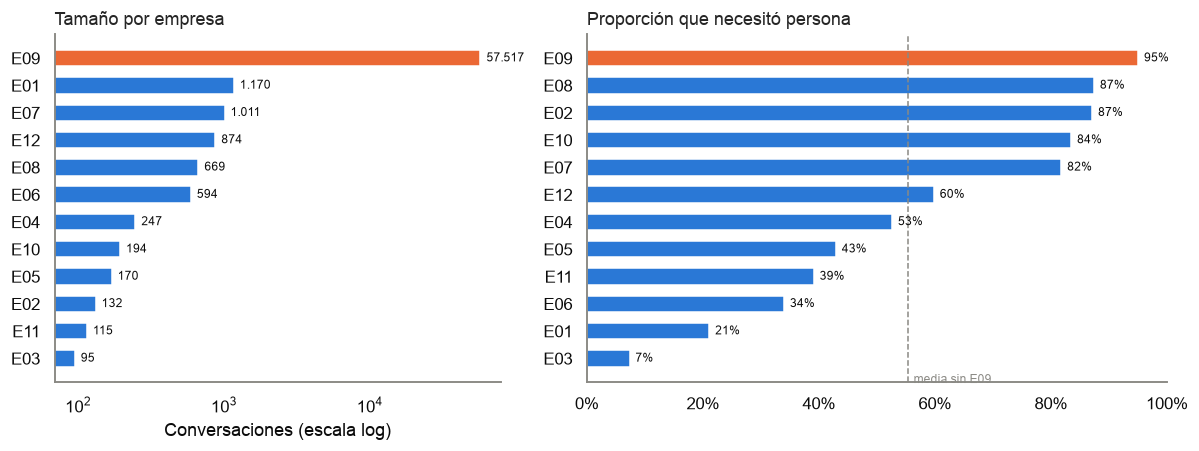

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
o = por_emp.sort_values("n")
a1.barh(o.index, o.n, color=[C1 if e == DOMINANT else C0 for e in o.index], height=0.6)
a1.set_xscale("log"); a1.set_xlabel("Conversaciones (escala log)"); a1.set_title("Tamaño por empresa", loc="left")
for y, v in enumerate(o.n): a1.text(v * 1.1, y, f"{v:,}".replace(",", "."), va="center", fontsize=8, color=INK)
o2 = por_emp.sort_values("tasa")
a2.barh(o2.index, o2.tasa, color=[C1 if e == DOMINANT else C0 for e in o2.index], height=0.6)
a2.axvline(df[df.empresa != DOMINANT][TARGET].mean(), color=MUTED, ls="--", lw=1)
a2.text(df[df.empresa != DOMINANT][TARGET].mean() + 0.01, -0.9, "media sin E09", color=MUTED, fontsize=8)
a2.set_xlim(0, 1); a2.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
a2.set_title("Proporción que necesitó persona", loc="left")
for y, v in enumerate(o2.tasa): a2.text(v + 0.01, y, f"{v:.0%}", va="center", fontsize=8, color=INK)
fig.tight_layout(); save(fig, "01_empresas"); plt.show()

**Decisión: el conjunto principal excluye a E09.**

- E09 aporta el **92 %** de las filas y en ella interviene una persona en el **95 %** de los casos,
  porque su operación es mixta por diseño. Con E09 adentro, un modelo que prediga siempre 1 acierta
  casi siempre, y las métricas reflejan la operación de E09, no el problema.
- Sin E09 quedan unas 5.300 conversaciones con **55 % de positivos**, prácticamente balanceadas.
  Ese es el conjunto donde la pregunta tiene sentido.
- La proporción va de 7 % a 95 % según la empresa, así que **la empresa por sí sola predice mucho**.
  Un modelo que sirva para negocios nuevos no puede apoyarse en ella: por eso se valida también
  dejando empresas fuera.

E09 se conserva como escenario secundario (se reporta, pero no guía decisiones).

In [7]:
rest = df[df.empresa != DOMINANT].copy()
print(f"Sin {DOMINANT}: {len(rest):,} filas, {rest.cliente.nunique():,} clientes, "
      f"{rest.empresa.nunique()} empresas, positivos {rest[TARGET].mean():.1%}")
print("Clientes que aparecen en más de una empresa:", (rest.groupby("cliente").empresa.nunique() > 1).sum())

Sin E09: 5,271 filas, 3,507 clientes, 11 empresas, positivos 55.3%
Clientes que aparecen en más de una empresa: 0


## 3. Cobertura temporal y cambio de mezcla

In [8]:
mes = rest.groupby("mes")[TARGET].agg(n="size", tasa="mean")
mes.T.round(2)

mes,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,2026-10
n,6.00,46.0,61.00,74.00,52.00,46.00,187.00,19.00,21.00,39.00,2.0,73.00,104.00,215.00,1861.00,2465.00
tasa,0.67,0.8,0.92,0.92,0.94,0.87,0.46,0.79,0.86,0.92,0.5,0.71,0.68,0.42,0.64,0.44


Antes de julio de 2026 casi no había atención automática (de 2 a 187 conversaciones al mes fuera
de E09). **El periodo útil es julio–octubre de 2026**, y la separación temporal queda así:
entrenar con todo lo anterior al 1 de octubre y probar con octubre.

La tasa de positivos baja de 64 % en septiembre a 44 % en octubre. La pregunta es si cambió el
comportamiento o cambió la mezcla de empresas.

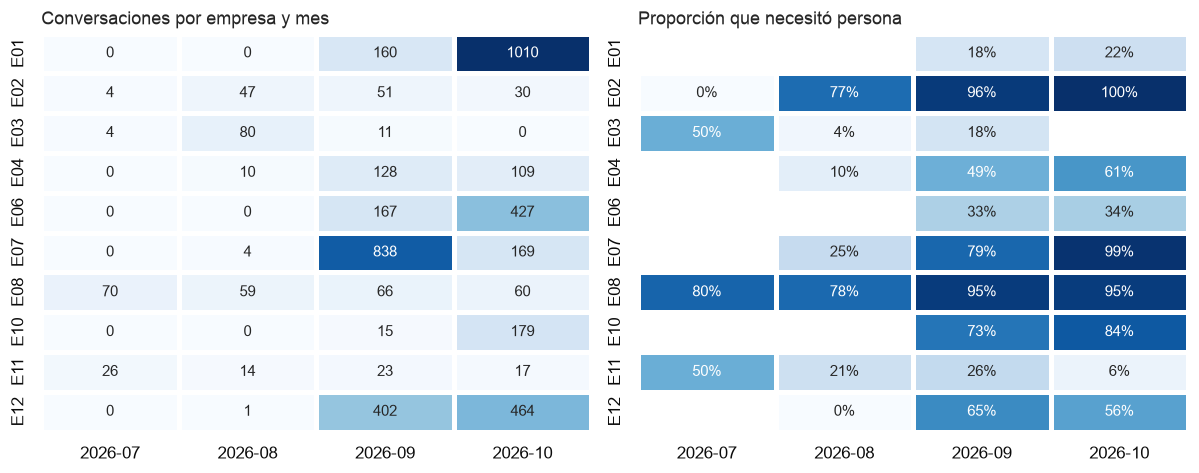

Sep real 64% | Oct real 44% | Oct esperada con tasas de sep y mezcla de oct: 42%


In [9]:
r4 = rest[rest.mes >= "2026-07"]
filas = pd.crosstab(r4.empresa, r4.mes)
tasas = r4.pivot_table(index="empresa", columns="mes", values=TARGET, aggfunc="mean")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.4))
sns.heatmap(filas, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a1, linewidths=2, linecolor="white")
a1.set_title("Conversaciones por empresa y mes", loc="left"); a1.set_xlabel(""); a1.set_ylabel("")
sns.heatmap(tasas, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=a2,
            linewidths=2, linecolor="white")
a2.set_title("Proporción que necesitó persona", loc="left"); a2.set_xlabel(""); a2.set_ylabel("")
fig.tight_layout(); save(fig, "02_empresa_mes"); plt.show()

# Expected October rate if each company kept its September rate: isolates the mix effect.
sep, oct_ = r4[r4.mes == "2026-09"], r4[r4.mes == "2026-10"]
tasa_sep = sep.groupby("empresa")[TARGET].mean()
peso_oct = oct_.empresa.value_counts(normalize=True)
esperada = (peso_oct * tasa_sep.reindex(peso_oct.index).fillna(sep[TARGET].mean())).sum()
print(f"Sep real {sep[TARGET].mean():.0%} | Oct real {oct_[TARGET].mean():.0%} | "
      f"Oct esperada con tasas de sep y mezcla de oct: {esperada:.0%}")

**La caída se explica casi entera por la mezcla.** E01 pasa de 160 a 1.010 conversaciones en octubre
y es de las empresas con menos intervención humana (22 %). Si cada empresa conservara su tasa de
septiembre, octubre tendría casi la misma proporción que se observó.

Consecuencias para el modelado:

- La prueba temporal mide **dos cosas a la vez**: generalizar en el tiempo y soportar un cambio en la
  proporción de positivos. Hay que reportarla junto con métricas por empresa.
- La **calibración** puede verse afectada: si el modelo no reconoce el cambio de mezcla, una
  probabilidad aprendida con 64 % de positivos sobreestimaría el riesgo en octubre. Queda como
  hipótesis para el notebook 02, que la pone a prueba (resultado: el modelo sí sigue el cambio de
  mezcla y no hace falta corregir).
- El **umbral** de decisión no debe fijarse en 0,5 por defecto. Se elige en validación con un
  criterio de negocio, por ejemplo recall ≥ 0,80.

## 4. Canal, hora y día

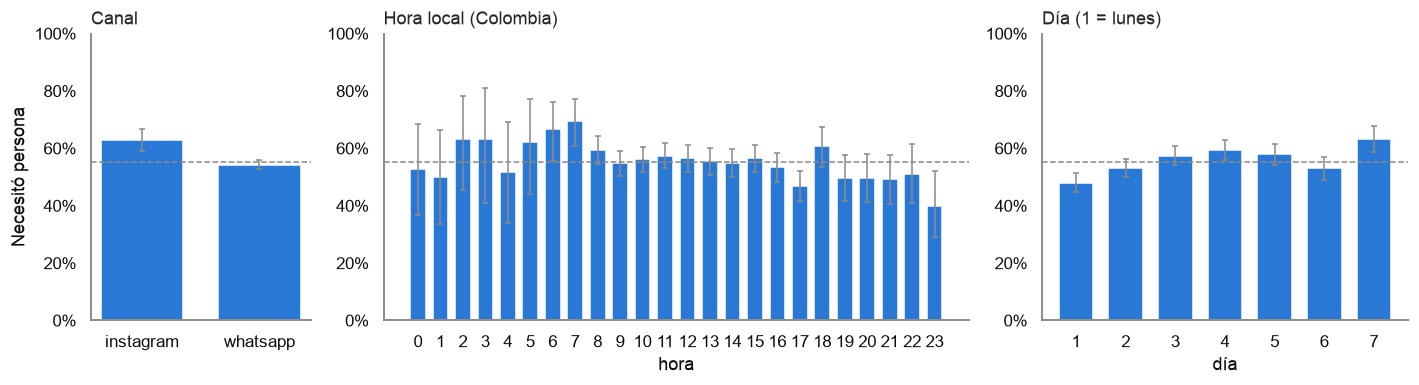

            mean  size
channel               
instagram  0.629   606
whatsapp   0.543  4665


In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [0.6, 1.6, 1]})
def tasa_bar(ax, g, title, xlabel):
    t = rest.groupby(g)[TARGET].agg(["mean", "size"])
    ci = np.array([wilson(m * n, n) for m, n in zip(t["mean"], t["size"])])
    ax.bar(t.index.astype(str), t["mean"], color=C0, width=0.7)
    ax.errorbar(t.index.astype(str), t["mean"], yerr=[t["mean"] - ci[:, 0], ci[:, 1] - t["mean"]],
                fmt="none", ecolor=MUTED, lw=1, capsize=2)
    ax.axhline(rest[TARGET].mean(), color=MUTED, ls="--", lw=1)
    ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    return t
t_canal = tasa_bar(axs[0], "channel", "Canal", "")
t_hora = tasa_bar(axs[1], "hour_local", "Hora local (Colombia)", "hora")
t_dia = tasa_bar(axs[2], "dow", "Día (1 = lunes)", "día")
axs[0].set_ylabel("Necesitó persona"); fig.tight_layout(); save(fig, "03_canal_hora_dia"); plt.show()
print(t_canal.round(3))

Las barras de error son intervalos de Wilson al 95 %, porque varias horas de la madrugada tienen
muy pocas conversaciones. La línea punteada es la media sin E09 (55 %).

- **Canal:** Instagram tiene algo más de intervención (63 % contra 54 %), pero solo aporta unas
  600 filas y depende de qué empresas lo usan.
- **Hora y día:** hay variación, pero los intervalos se solapan mucho. Son señales débiles, que
  conviene conservar porque son baratas y pueden interactuar con otras: fuera de horario puede haber
  menos personas disponibles.

## 5. Variables numéricas: distribución y relación con la etiqueta

In [11]:
num = ["w_customer_msgs", "w_ai_msgs", "cust_chars_mean", "cust_chars_max", "cust_question_marks",
       "first_ai_reply_s", "cust_gap_mean_s", "ai_chars_mean", "prior_conversations", "prior_needed_human"]
rest[num].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(1)

,count,mean,std,min,1%,25%,50%,75%,99%,max
w_customer_msgs,5271.0,2.1,0.5,1.0,1.0,2.0,2.0,2.0,4.0,4.0
w_ai_msgs,5271.0,1.9,0.5,0.0,0.0,2.0,2.0,2.0,3.0,3.0
cust_chars_mean,5271.0,57.0,88.4,1.0,4.0,13.5,25.5,56.5,399.8,1292.3
cust_chars_max,5271.0,91.7,143.8,1.0,4.0,20.0,34.0,79.0,674.6,2451.0
cust_question_marks,5271.0,0.3,0.6,0.0,0.0,0.0,0.0,1.0,2.0,10.0
first_ai_reply_s,5198.0,123.9,5399.0,-53240.7,3.5,5.8,12.2,19.3,82.2,337729.0
cust_gap_mean_s,4726.0,4856.3,71566.8,0.0,0.4,15.0,34.0,91.4,83679.8,3900630.8
ai_chars_mean,5198.0,462.4,528.6,3.0,35.5,131.1,266.0,689.0,1834.5,4530.0
prior_conversations,5271.0,3.3,9.1,0.0,0.0,0.0,0.0,2.0,45.3,97.0
prior_needed_human,5271.0,1.0,2.7,0.0,0.0,0.0,0.0,0.0,14.0,27.0


**Atípicos.** Las colas son muy largas: hay respuestas automáticas de más de 4.500 caracteres
(los menús cuentan su contenido estructurado), intervalos entre mensajes de días y tiempos de
primera respuesta negativos (47 filas, en las que el bot escribió primero). No son errores, son
parte del fenómeno. Por eso **no se eliminan**: se transforman con un logaritmo con signo
`sign(x)·log(1+|x|)`, que comprime la cola y conserva el orden y los negativos. Los árboles no lo
necesitan, pero kNN, SVM y la regresión logística sí.

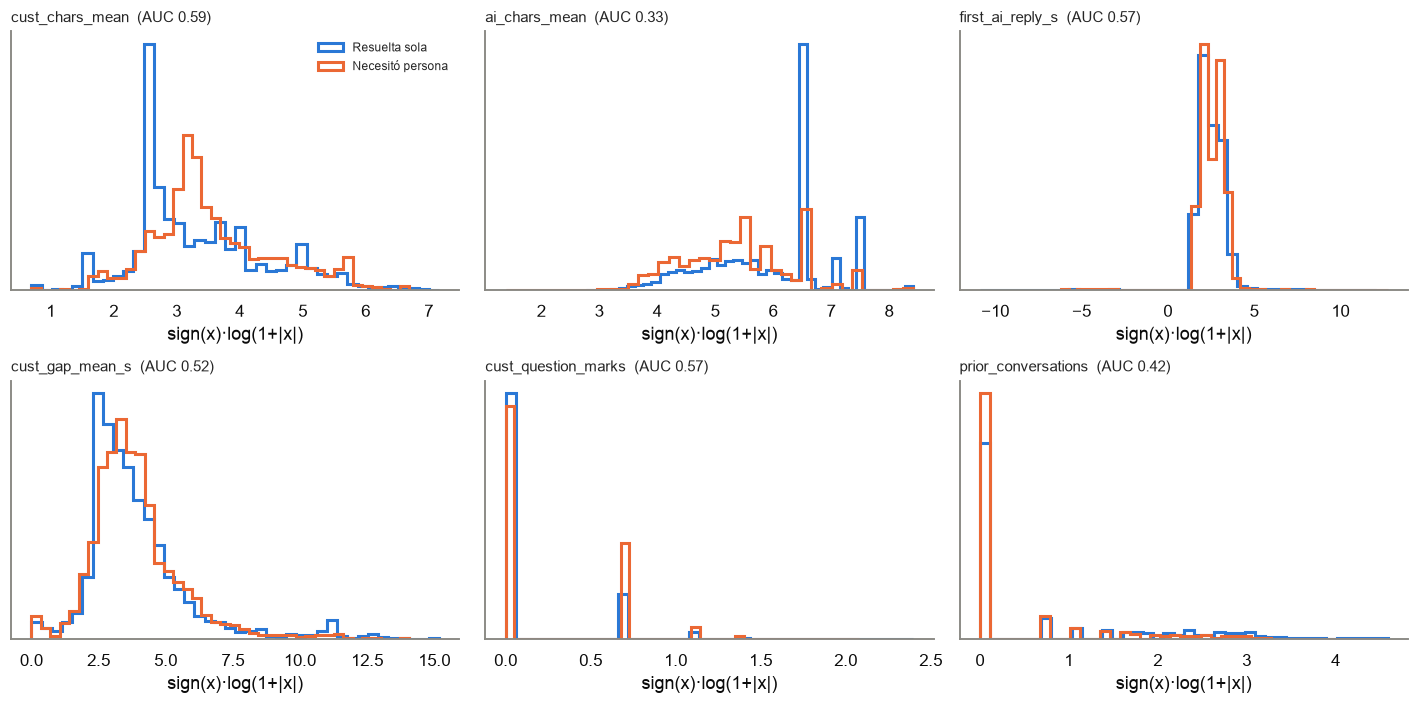

In [12]:
from features import signed_log
cols = ["cust_chars_mean", "ai_chars_mean", "first_ai_reply_s", "cust_gap_mean_s", "cust_question_marks", "prior_conversations"]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axs.flat, cols):
    for y, col, lab in [(0, C0, "Resuelta sola"), (1, C1, "Necesitó persona")]:
        v = signed_log(rest.loc[rest[TARGET] == y, c].dropna())
        ax.hist(v, bins=40, density=True, histtype="step", lw=2, color=col, label=lab)
    v = rest[c].dropna(); auc = roc_auc_score(rest.loc[v.index, TARGET], v)
    ax.set_title(f"{c}  (AUC {auc:.2f})", loc="left", fontsize=10); ax.set_xlabel("sign(x)·log(1+|x|)")
    ax.set_yticks([])
axs[0, 0].legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "04_distribuciones"); plt.show()

El AUC del título usa la variable cruda como puntaje. 0,5 es no separar nada, y por debajo de 0,5
significa que la relación va al revés: valores altos, menos intervención.

- `ai_chars_mean` es la que más separa sola. **Respuestas automáticas largas se asocian a menos
  intervención humana.** La sección 6 revisa si eso es comportamiento o identidad de la empresa.
- `prior_conversations`: los clientes que vuelven necesitan menos a una persona.
- `cust_question_marks`: más preguntas, más intervención.

### Clientes que vuelven

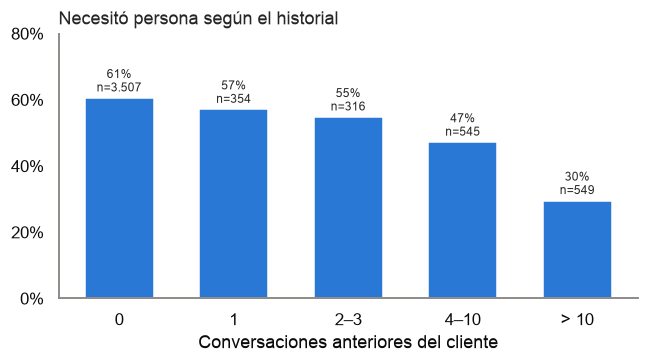

Con historial: AUC de prior_needed_human / prior_conversations = 0.842


In [13]:
b = pd.cut(rest.prior_conversations, [-1, 0, 1, 3, 10, 1000], labels=["0", "1", "2–3", "4–10", "> 10"])
h = rest.groupby(b, observed=True)[TARGET].agg(n="size", tasa="mean")
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(h.index.astype(str), h.tasa, color=C0, width=0.6)
for x, (n, t) in enumerate(zip(h.n, h.tasa)): ax.text(x, t + 0.02, f"{t:.0%}\nn={n:,}".replace(",", "."), ha="center", fontsize=8)
ax.set_ylim(0, 0.8); ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Conversaciones anteriores del cliente"); ax.set_title("Necesitó persona según el historial", loc="left")
fig.tight_layout(); save(fig, "05_historial"); plt.show()

con_hist = rest[rest.prior_conversations > 0]
print("Con historial: AUC de prior_needed_human / prior_conversations =",
      round(roc_auc_score(con_hist[TARGET], con_hist.prior_needed_human / con_hist.prior_conversations), 3))

Hay un gradiente claro: 60 % sin historial contra 28 % con más de 10 conversaciones anteriores.
Para los que tienen historial, **la proporción de sus conversaciones pasadas que necesitaron
persona** es buena señal, y se agrega como variable `prior_human_rate`.

*Cuidado con la fuga:* el historial solo cuenta conversaciones **anteriores** del mismo cliente.
Si una conversación anterior seguía abierta cuando empezó la actual, su etiqueta podría no
conocerse aún en producción. Es un caso de borde que se menciona como limitación.

### Señales escasas

In [14]:
esc = ["cust_repeats", "media_image", "media_audio", "media_document", "media_other",
       "ai_no_info", "cust_asks_human", "cust_negative_words"]
rows = []
for c in esc:
    on = rest[rest[c] > 0]; lo, hi = wilson(on[TARGET].sum(), len(on))
    rows.append({"variable": c, "% ceros": (rest[c] == 0).mean(), "filas > 0": len(on),
                 "tasa si > 0": on[TARGET].mean(), "IC 95 %": f"{lo:.0%}–{hi:.0%}"})
pd.DataFrame(rows).set_index("variable").style.format({"% ceros": "{:.1%}", "tasa si > 0": "{:.0%}"})

,% ceros,filas > 0,tasa si > 0,IC 95 %
variable,,,,
cust_repeats,98.2%,94,39%,30%–49%
media_image,93.8%,325,61%,55%–66%
media_audio,98.4%,82,84%,75%–90%
media_document,99.3%,39,18%,9%–33%
media_other,97.9%,111,59%,49%–67%
ai_no_info,98.6%,75,60%,49%–70%
cust_asks_human,99.4%,30,67%,49%–81%
cust_negative_words,99.7%,14,50%,27%–73%


Entre 94 % y 100 % de ceros. Es esperable: la ventana es corta (4 mensajes) y muchos clientes
tocan botones de menú en vez de escribir. Con tan pocos casos, los intervalos son anchos y la
mayoría se solapan con la media del 55 %.

**Decisión:** se conservan porque son interpretables y útiles en la interfaz ("el cliente pidió un
asesor"), y los adjuntos se agregan además en `has_media`. Ningún modelo puede aprender mucho de
16 a 75 casos, y así se reporta. Si hiciera falta más señal, se puede regenerar el conjunto con una
ventana de hasta 8 mensajes.

## 6. ¿`ai_chars_mean` mide comportamiento o identidad de la empresa?

Cada empresa configura su agente de forma distinta. Algunas responden con menús largos y otras con
frases cortas. Si el largo de las respuestas solo identifica a la empresa, el modelo estaría
aprendiendo "esta es E01, que casi no escala", lo que no sirve para empresas nuevas.

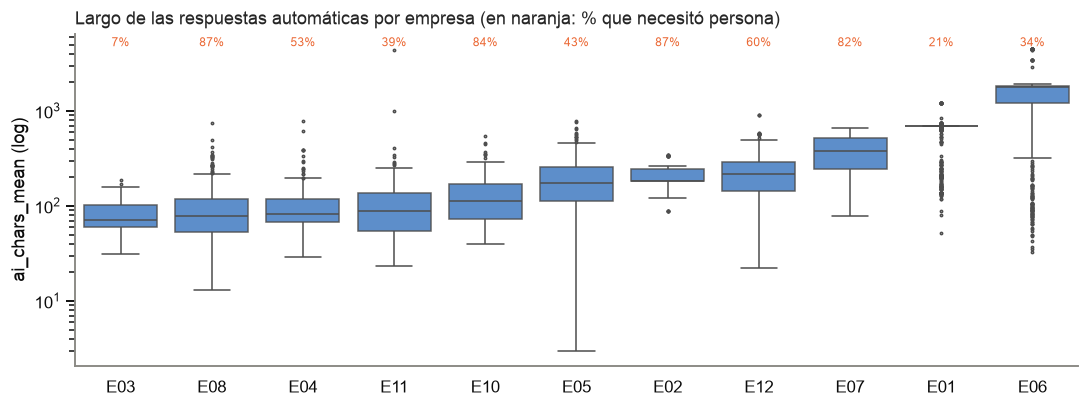

In [15]:
orden = rest.groupby("empresa").ai_chars_mean.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 3.8))
sns.boxplot(data=rest, x="empresa", y="ai_chars_mean", order=orden, color=C0, fliersize=1.5,
            linewidth=1, ax=ax, boxprops={"alpha": .85})
ax.set_yscale("log"); ax.set_ylabel("ai_chars_mean (log)"); ax.set_xlabel("")
tx = ax.twinx(); tx.set_yticks([]); tx.spines[:].set_visible(False)
for x, e in enumerate(orden):
    ax.text(x, 4800, f"{por_emp.loc[e, 'tasa']:.0%}", ha="center", fontsize=8, color=C1)
ax.set_title("Largo de las respuestas automáticas por empresa (en naranja: % que necesitó persona)", loc="left")
fig.tight_layout(); save(fig, "06_ai_chars_empresa"); plt.show()

In [16]:
# How much of the company identity does this single feature carry?
cv = StratifiedKFold(5, shuffle=True, random_state=0)
Xa = rest[["ai_chars_mean"]].fillna(-1)
acc = cross_val_score(DecisionTreeClassifier(max_depth=6, random_state=0), Xa, rest.empresa, cv=cv).mean()
print(f"Adivinar la empresa (11 clases) solo con ai_chars_mean: exactitud {acc:.0%} "
      f"(clase mayoritaria: {rest.empresa.value_counts(normalize=True).max():.0%})")

auc_pooled = roc_auc_score(rest.dropna(subset=['ai_chars_mean'])[TARGET], -rest.ai_chars_mean.dropna())
dentro = {e: roc_auc_score(g[TARGET], -g.ai_chars_mean) for e, g in rest.dropna(subset=["ai_chars_mean"]).groupby("empresa")
          if g[TARGET].nunique() > 1 and len(g) >= 50}
print(f"AUC de -ai_chars_mean mezclando empresas: {auc_pooled:.2f}")
print("AUC dentro de cada empresa:", {k: round(v, 2) for k, v in dentro.items()})
print(f"Promedio dentro de empresa: {np.mean(list(dentro.values())):.2f}")

Adivinar la empresa (11 clases) solo con ai_chars_mean: exactitud 67% (clase mayoritaria: 22%)
AUC de -ai_chars_mean mezclando empresas: 0.67
AUC dentro de cada empresa: {'E01': 0.45, 'E02': 0.4, 'E03': 0.46, 'E04': 0.57, 'E05': 0.53, 'E06': 0.56, 'E07': 0.59, 'E08': 0.52, 'E10': 0.51, 'E11': 0.56, 'E12': 0.51}
Promedio dentro de empresa: 0.51


**Lectura.** Mezclando empresas, `-ai_chars_mean` tiene AUC 0,67, pero **dentro de cada empresa
el AUC va de 0,40 a 0,59 y promedia 0,51, es decir, azar**. En algunas empresas la relación incluso
se invierte. Además, con esa sola variable se adivina la empresa en el 67 % de los
casos (la clase mayoritaria es el 22 %). Es una **huella de la empresa**: separa empresas, no
conversaciones. Dentro de un mismo negocio, que la respuesta sea larga o corta no dice nada sobre
si va a hacer falta una persona.

Para no sacar conclusiones de una sola variable, la misma prueba se hace con todas: AUC
mezclando empresas contra el AUC promedio dentro de cada empresa (ponderado por tamaño, empresas
con ≥ 50 filas y ambas clases). Una variable útil para negocios nuevos debe conservar su AUC
dentro de las empresas.

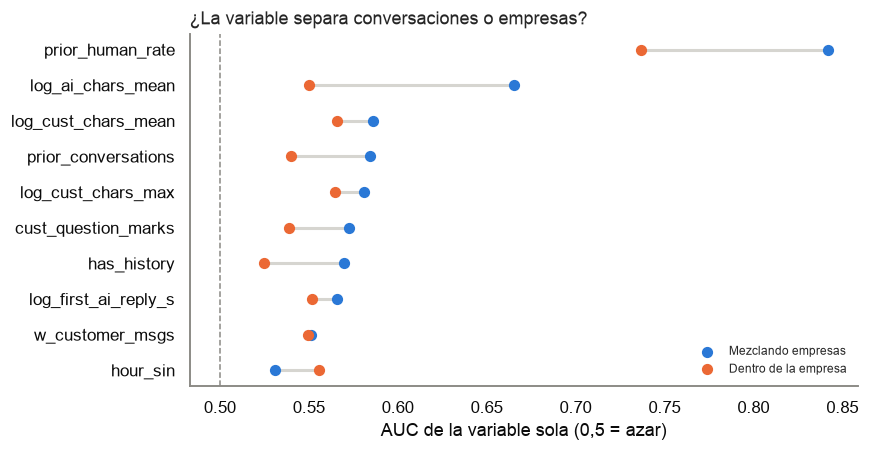

,mezclando empresas,dentro de la empresa
variable,,
hour_sin,0.53,0.56
w_customer_msgs,0.55,0.55
log_first_ai_reply_s,0.57,0.55
has_history,0.57,0.52
cust_question_marks,0.57,0.54
log_cust_chars_max,0.58,0.56
prior_conversations,0.58,0.54
log_cust_chars_mean,0.59,0.57
log_ai_chars_mean,0.67,0.55


In [17]:
def auc_dir(y, s):
    a = roc_auc_score(y, s); return max(a, 1 - a)   # direction-agnostic separation
feats = build_features(rest).drop(columns=[f"dow_{d}" for d in range(1, 8)])
filas_ = []
for c in feats.columns:
    v = feats[c]; ok = v.notna()
    if v[ok].nunique() < 2: continue
    pooled = auc_dir(rest.loc[ok, TARGET], v[ok])
    w = [(len(g), auc_dir(g[TARGET], v[g.index])) for e, g in rest[ok].groupby("empresa")
         if g[TARGET].nunique() > 1 and len(g) >= 50 and v[g.index].nunique() > 1]
    within = np.average([a for _, a in w], weights=[n for n, _ in w]) if w else np.nan
    filas_.append({"variable": c, "mezclando empresas": pooled, "dentro de la empresa": within})
sep_tab = pd.DataFrame(filas_).set_index("variable").sort_values("mezclando empresas")
sep_tab = sep_tab[sep_tab["mezclando empresas"] > 0.53]

fig, ax = plt.subplots(figsize=(8, 0.32 * len(sep_tab) + 1))
yy = np.arange(len(sep_tab))
ax.hlines(yy, sep_tab["dentro de la empresa"], sep_tab["mezclando empresas"], color="#d6d5d0", lw=2)
ax.scatter(sep_tab["mezclando empresas"], yy, color=C0, s=40, zorder=3, label="Mezclando empresas")
ax.scatter(sep_tab["dentro de la empresa"], yy, color=C1, s=40, zorder=3, label="Dentro de la empresa")
ax.set_yticks(yy, sep_tab.index); ax.axvline(0.5, color=MUTED, ls="--", lw=1)
ax.set_xlabel("AUC de la variable sola (0,5 = azar)"); ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.set_title("¿La variable separa conversaciones o empresas?", loc="left")
fig.tight_layout(); save(fig, "06b_auc_dentro_empresa"); plt.show()
sep_tab.round(2)

- **`ai_chars_mean` es el caso más claro de huella:** es la que más pierde, de 0,67 a 0,55, al
  nivel de variables débiles como la hora.
- **El historial del cliente sí es señal real.** `prior_human_rate` (calculada solo para clientes
  con historial) pasa de 0,84 a 0,74 y sigue siendo de lejos la mejor dentro de cada empresa: un
  cliente que antes necesitó a una persona tiende a volver a necesitarla.
- El resto (largo de los mensajes del cliente, preguntas, tiempo de respuesta, hora) queda entre
  0,52 y 0,57, tanto mezclando empresas como dentro de ellas: señales débiles pero honestas.

**Decisión para el modelado:**
- entrenar y reportar **con y sin** `ai_chars_mean`. Se espera que ayude en la prueba temporal,
  donde las empresas son las mismas, y que no ayude, o incluso estorbe, con empresas no vistas;
- el modelo que se despliegue para empresas nuevas no debe depender de ella;
- en SHAP, mostrar que su efecto coincide con la identidad de la empresa.

## 7. Correlaciones entre variables

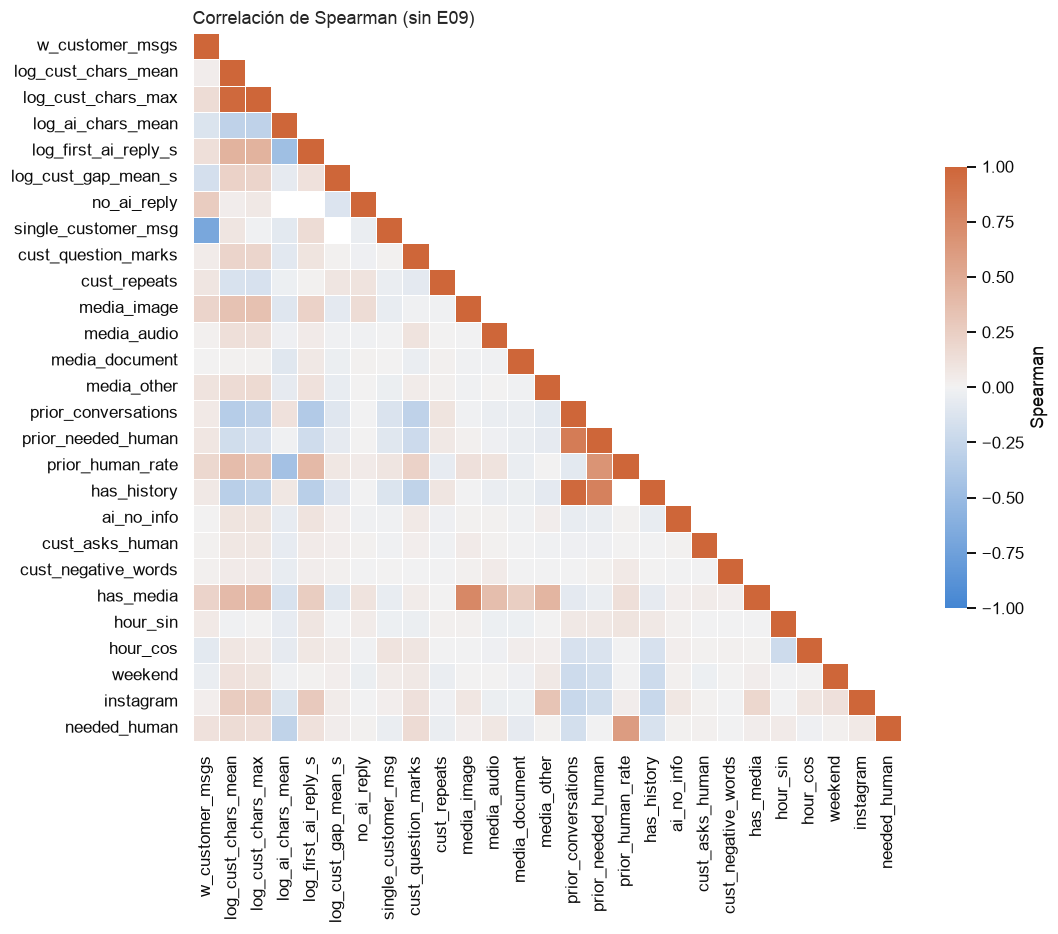

Pares con |ρ| > 0,7:
has_history          prior_conversations    0.97
log_cust_chars_max   log_cust_chars_mean    0.97
prior_conversations  prior_needed_human     0.84
has_history          prior_needed_human     0.80
media_image          has_media              0.76


In [18]:
X_eda = build_features(rest)
corr = pd.concat([X_eda, rest[TARGET]], axis=1).drop(columns=[f"dow_{d}" for d in range(1, 8)]).corr("spearman")
fig, ax = plt.subplots(figsize=(10, 8.5))
mask = np.triu(np.ones_like(corr, bool), 1)
sns.heatmap(corr, mask=mask, cmap=sns.diverging_palette(250, 25, s=80, l=55, as_cmap=True), center=0,
            vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .6, "label": "Spearman"}, ax=ax)
ax.set_title("Correlación de Spearman (sin E09)", loc="left"); fig.tight_layout(); save(fig, "07_correlaciones"); plt.show()
alta = corr.where(~np.eye(len(corr), dtype=bool)).abs().stack().sort_values(ascending=False)
alta = alta[alta > 0.7].iloc[::2]
print("Pares con |ρ| > 0,7:"); print(alta.round(2).to_string())

Las parejas muy correlacionadas son esperables por construcción (`cust_chars_mean` con
`cust_chars_max`, `prior_conversations` con `prior_needed_human` y `has_history`, `has_media` con
`media_image`). Mensajes del cliente y de la IA en la ventana suman 4, así que son la misma
información y solo se conserva `w_customer_msgs`; el caso "la IA no respondió" ya queda en
`no_ai_reply`. Para los árboles no es problema. En la regresión logística se
controla con regularización L2. SHAP reparte la importancia entre variables correlacionadas, y hay
que tenerlo en cuenta al leerlo.

## 8. Preprocesamiento final

La función `build_features` (en `src/features.py`) solo hace transformaciones **fila a fila**, sin
estadísticas del conjunto, así que no puede filtrar información de la prueba:

| Grupo | Transformación |
|---|---|
| Largos y tiempos | `sign(x)·log(1+|x|)` |
| Conteos (preguntas, repeticiones, adjuntos, historial) | `log(1+x)` |
| Mensajes de la IA en la ventana | se descarta (`= 4 − w_customer_msgs`) |
| Faltantes informativos | `no_ai_reply`, `single_customer_msg` |
| Historial | `prior_human_rate`, `has_history` |
| Adjuntos | `has_media` |
| Hora | seno y coseno (las 23 h quedan junto a las 0 h) |
| Día | one-hot + `weekend` |
| Canal | `instagram` (0/1) |

Lo que sí se aprende de los datos va dentro de un `Pipeline` de sklearn y se ajusta **solo con
entrenamiento**: imputación con la mediana (`prior_human_rate` y los vacíos de largos y tiempos) y
escalado estándar para kNN, SVM y regresión logística.

**Desbalance:** sin E09 hay 55/45, así que no hace falta sobremuestrear. Se usa
`class_weight="balanced"` donde aplique y el umbral se elige por criterio de negocio.

In [19]:
X = build_features(rest); y = rest[TARGET]
print(X.shape); X.describe().T[["mean", "min", "max"]].round(2)

(5271, 33)


,mean,min,max
w_customer_msgs,2.06,1.00,4.00
log_cust_chars_mean,3.46,0.69,7.16
log_cust_chars_max,3.84,0.69,7.80
log_ai_chars_mean,5.64,1.39,8.42
log_first_ai_reply_s,2.51,-10.88,12.73
log_cust_gap_mean_s,3.91,0.00,15.18
no_ai_reply,0.01,0.00,1.00
single_customer_msg,0.10,0.00,1.00
cust_question_marks,0.20,0.00,2.40
cust_repeats,0.01,0.00,1.39


## 9. Esquemas de validación y control de fuga

In [20]:
tr, te = time_split(rest)
comp = set(tr.cliente) & set(te.cliente)
print(f"Temporal → entrenamiento {len(tr):,} (pos {tr[TARGET].mean():.0%}) | prueba {len(te):,} (pos {te[TARGET].mean():.0%})")
print(f"Clientes en ambos lados: {len(comp):,} ({te.cliente.isin(comp).mean():.0%} de las filas de prueba)")
nuevos = te[~te.cliente.isin(comp)]
print(f"Prueba solo con clientes nuevos: {len(nuevos):,} filas (pos {nuevos[TARGET].mean():.0%})")
print("Empresas en prueba que no están en entrenamiento:", sorted(set(te.empresa) - set(tr.empresa)))

Temporal → entrenamiento 2,806 (pos 65%) | prueba 2,465 (pos 44%)
Clientes en ambos lados: 120 (36% de las filas de prueba)
Prueba solo con clientes nuevos: 1,577 filas (pos 54%)
Empresas en prueba que no están en entrenamiento: []


**Tres esquemas, cada uno responde una pregunta distinta:**

1. **Temporal (resultado principal):** entrenar con todo lo anterior a octubre y probar con
   octubre. Es lo que pasaría en producción. Que un cliente aparezca en ambos lados es **legítimo
   aquí**: en producción el modelo también ve clientes que vuelven, y su pasado entra solo por las
   variables de historial. Aun así, se reporta además la métrica **solo con clientes nuevos** para
   mostrar que el resultado no depende de recordar clientes.
2. **Ajuste de hiperparámetros:** dentro del entrenamiento, `StratifiedGroupKFold` agrupando por
   **cliente**, para que las conversaciones de un mismo cliente no queden en entrenamiento y en
   validación a la vez.
3. **Empresas no vistas:** `LeaveOneGroupOut` por empresa. Mide si el modelo sirve para un negocio
   nuevo. Es la prueba más difícil, y la línea base da ROC-AUC 0,65.

## 10. Conclusiones del EDA

1. **Conjunto principal sin E09** (≈ 5.300 filas, 55 % positivos). E09 distorsiona las métricas
   y se reporta aparte.
2. **El periodo útil es julio–octubre de 2026.** La separación temporal jul–sep → oct es la
   evaluación principal.
3. **Cambio de mezcla en octubre:** la caída de 64 % a 44 % se explica por qué empresas
   escribieron, no por un cambio de comportamiento. Esto obliga a reportar métricas por empresa
   y a revisar la calibración y el umbral en el notebook 02.
4. **Las señales más fuertes vistas de a una** son el largo de las respuestas automáticas, el historial del
   cliente y la cantidad de preguntas. Hora, día y canal son débiles.
5. **`ai_chars_mean` es una huella de la empresa:** AUC 0,67 mezclando empresas y 0,51 dentro de
   ellas (0,55 sin importar la dirección). Se evalúa con y sin ella y se discute con SHAP. **El historial del cliente, en cambio, sí
   es señal dentro de cada empresa.**
6. **Las señales de texto y adjuntos son escasas** (94–100 % de ceros). Son interpretables pero de
   poco peso estadístico.
7. **Faltantes informativos** convertidos en indicadores, atípicos conservados y transformados con
   logaritmo, y preprocesamiento ajustado solo con entrenamiento.

**Siguiente notebook:** `02_modelado.ipynb`, que compara las líneas base, kNN, SVM, árbol, RF y
Gradient Boosting con validación agrupada, ajusta hiperparámetros, elige el umbral, calibra y
corre SHAP.

# Parte 2 · Modelado, selección, umbral, calibración y explicabilidad

Cubre los puntos **3.5 (modelos y selección)**, **3.6 (generalización)** y **3.7 (métricas)**
del enunciado, a partir de las decisiones del notebook 01:

- conjunto principal **sin E09**;
- evaluación principal: **entrenar con todo lo anterior a octubre y probar con octubre**, también
  solo con clientes nuevos;
- generalización a negocios nuevos: **dejar fuera una empresa a la vez**;
- todo **con y sin `ai_chars_mean`**, que en el EDA resultó ser una huella de la empresa.

Al final se guarda el modelo desplegable en `models/` y las métricas que usa `model_card.md`.

In [21]:
import os, sys, json, time, warnings
os.environ["PYTHONWARNINGS"] = "ignore"   # silence joblib worker warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, shap
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold, learning_curve
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_recall_curve,
                             recall_score, precision_score, brier_score_loss, confusion_matrix)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load, build_features, time_split, TARGET, DOMINANT
from risk_model import (DROP, make_rf, group_splits, calibrated, shift_prior, estimate_prior_em,
                        threshold_for_recall, RiskModel, explain, train_risk_model)

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"; MODELS = ROOT / "models"; FIG.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
C0, C1, C2, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
sns.set_theme(style="white", rc={"axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                                 "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)
RNG = 0

df = load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv")
rest = df[df.empresa != DOMINANT].reset_index(drop=True)
tr, te = time_split(rest)
new_cust = ~te.cliente.isin(set(tr.cliente)).values
VARIANTS = {"con ai_chars_mean": (), "sin ai_chars_mean": DROP}
y_tr, y_te = tr[TARGET].values, te[TARGET].values
print(f"Entrenamiento {len(tr):,} (pos {y_tr.mean():.0%}) | octubre {len(te):,} (pos {y_te.mean():.0%}) | "
      f"octubre solo clientes nuevos {new_cust.sum():,} (pos {y_te[new_cust].mean():.0%})")

Entrenamiento 2,806 (pos 65%) | octubre 2,465 (pos 44%) | octubre solo clientes nuevos 1,577 (pos 54%)


## 1. Modelos candidatos y búsqueda de hiperparámetros

- **Líneas base:** predecir siempre la clase mayoritaria, y regresión logística (lineal, interpretable).
- **Candidatos:** kNN, SVM con kernel RBF, árbol de decisión, Random Forest y Gradient Boosting
  (`HistGradientBoostingClassifier`).
- **Preprocesamiento dentro del `Pipeline`:** imputación con la mediana y, para logística, kNN y SVM,
  escalado estándar. Se ajusta en cada pliegue solo con su parte de entrenamiento.
- **Búsqueda aleatoria** de 20 combinaciones por modelo, con `StratifiedGroupKFold` de 5 pliegues
  **agrupado por cliente**, optimizando **PR-AUC** (la métrica principal, ver sección 5).
- `class_weight="balanced"` donde aplica. La probabilidad se recalibra después.

In [22]:
imp = lambda: SimpleImputer(strategy="median")
CANDIDATOS = {
    "Mayoritaria": (DummyClassifier(strategy="prior"), None),
    "Logística": (make_pipeline(imp(), StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
                  {"logisticregression__C": loguniform(1e-3, 1e2)}),
    "kNN": (make_pipeline(imp(), StandardScaler(), KNeighborsClassifier()),
            {"kneighborsclassifier__n_neighbors": randint(5, 150), "kneighborsclassifier__weights": ["uniform", "distance"]}),
    "SVM": (make_pipeline(imp(), StandardScaler(), SVC(class_weight="balanced")),
            {"svc__C": loguniform(1e-2, 1e2), "svc__gamma": loguniform(1e-4, 1e0)}),
    "Árbol": (make_pipeline(imp(), DecisionTreeClassifier(class_weight="balanced", random_state=RNG)),
              {"decisiontreeclassifier__max_depth": randint(2, 12), "decisiontreeclassifier__min_samples_leaf": randint(5, 100)}),
    "Random Forest": (make_rf(), {"rf__max_depth": [4, 6, 8, 12, None], "rf__min_samples_leaf": randint(1, 40),
                                  "rf__max_features": uniform(0.1, 0.6)}),
    "Gradient Boosting": (HistGradientBoostingClassifier(class_weight="balanced", random_state=RNG),
                          {"learning_rate": loguniform(0.01, 0.3), "max_depth": [2, 3, 4, 6, None],
                           "min_samples_leaf": randint(10, 200), "l2_regularization": loguniform(1e-3, 10),
                           "max_iter": randint(100, 500)}),
}
def score(m, X): return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)
cv = StratifiedGroupKFold(5, shuffle=True, random_state=RNG)

In [23]:
def leave_one_company_out(est, drop):
    X_all = build_features(rest, drop); out = []
    for e in sorted(rest.empresa.unique()):
        m = (rest.empresa == e).values
        if rest[TARGET][m].nunique() < 2: continue
        fit = clone(est).fit(X_all[~m], rest[TARGET][~m])
        out.append(pd.DataFrame({"y": rest[TARGET][m].values, "p": score(fit, X_all[m]), "empresa": e}))
    return pd.concat(out)

resultados, mejores, logo = [], {}, {}
for variante, drop in VARIANTS.items():
    Xtr, Xte = build_features(tr, drop), build_features(te, drop)
    for nombre, (est, grid) in CANDIDATOS.items():
        t0 = time.time()
        if grid is None:
            best = clone(est).fit(Xtr, y_tr); cv_mean, cv_std, params = np.nan, np.nan, {}
        else:
            s = RandomizedSearchCV(est, grid, n_iter=20, cv=cv, scoring="average_precision", n_jobs=-1,
                                   random_state=RNG).fit(Xtr, y_tr, groups=tr.cliente)
            best, params = s.best_estimator_, s.best_params_
            cv_mean, cv_std = s.best_score_, s.cv_results_["std_test_score"][s.best_index_]
        p = score(best, Xte)
        lo = leave_one_company_out(best, drop) if grid is not None else None
        mejores[(variante, nombre)], logo[(variante, nombre)] = best, lo
        resultados.append({
            "variante": variante, "modelo": nombre, "PR-AUC CV": cv_mean, "± CV": cv_std,
            "ROC-AUC oct": roc_auc_score(y_te, p), "PR-AUC oct": average_precision_score(y_te, p),
            "ROC-AUC oct nuevos": roc_auc_score(y_te[new_cust], p[new_cust]),
            "ROC-AUC empresas no vistas": roc_auc_score(lo.y, lo.p) if lo is not None else np.nan,
            "ROC-AUC medio por empresa": np.mean([roc_auc_score(g.y, g.p) for _, g in lo.groupby("empresa")]) if lo is not None else np.nan,
            "seg": round(time.time() - t0), "params": params})
R = pd.DataFrame(resultados)
R.drop(columns="params").set_index(["variante", "modelo"]).round(3)

PR-AUC CV   ± CV  ROC-AUC oct  PR-AUC oct  ROC-AUC oct nuevos  ROC-AUC empresas no vistas  ROC-AUC medio por empresa  seg
variante          modelo                                                                                                                                      
con ai_chars_mean Mayoritaria              NaN    NaN        0.500       0.445               0.500                         NaN                        NaN    0
                  Logística              0.831  0.013        0.777       0.731               0.716                       0.702                      0.637    2
                  kNN                    0.845  0.014        0.699       0.634               0.618                       0.544                      0.605    1
                  SVM                    0.851  0.007        0.763       0.734               0.725                       0.672                      0.641    7
                  Árbol                  0.847  0.014        0.790       0.753               0.741                       0.687                      0.585    1
                  Random Forest          0.886  0.010        0.808       0.795               0.765                       0.706                      0.631   16
                  Gradient Boosting      0.878  0.003        0.813       0.796               0.765                       0.679                      0.625   17
sin ai_chars_mean Mayoritaria              NaN    NaN        0.500       0.445               0.500                         NaN                        NaN    0
                  Logística              0.830  0.015        0.753       0.704               0.672                       0.653                      0.638    1
                  kNN                    0.838  0.017        0.684       0.624               0.612                       0.504                      0.613    1
                  SVM                    0.837  0.012        0.736       0.688               0.663                       0.623                      0.638    7
                  Árbol                  0.838  0.015        0.758       0.712               0.708                       0.526                      0.614    1
                  Random Forest          0.872  0.015        0.786       0.771               0.736                       0.694                      0.639   15
                  Gradient Boosting      0.866  0.010        0.790       0.772               0.733                       0.679                      0.636   15

**Cómo leer la tabla.**
- *PR-AUC CV*: validación cruzada dentro del entrenamiento (jul–sep), agrupada por cliente. Es la
  que guía la búsqueda.
- *Octubre*: prueba temporal, el resultado principal. El azar en PR-AUC es la proporción de
  positivos de octubre (0,44).
- *Octubre nuevos*: solo clientes que no aparecen en el entrenamiento.
- *Empresas no vistas*: cada empresa se predice con un modelo entrenado sin ella, y se juntan las
  predicciones.
- *Medio por empresa*: el AUC calculado dentro de cada empresa y promediado. Mide si el modelo
  **ordena bien las conversaciones de un mismo negocio**, que es lo que necesita la cola de
  atención.

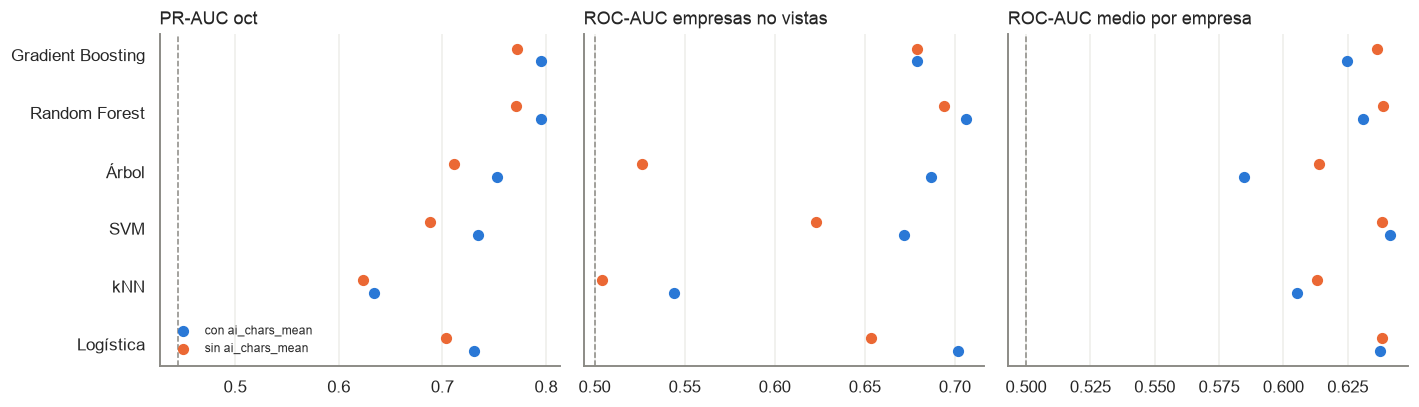

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
orden = [m for m in CANDIDATOS if m != "Mayoritaria"]
for ax, col, ref in zip(axs, ["PR-AUC oct", "ROC-AUC empresas no vistas", "ROC-AUC medio por empresa"],
                        [y_te.mean(), 0.5, 0.5]):
    for i, (v, c) in enumerate(zip(VARIANTS, [C0, C1])):
        s = R[R.variante == v].set_index("modelo").loc[orden, col]
        ax.scatter(s.values, np.arange(len(orden)) + (i - 0.5) * 0.22, color=c, s=40, label=v, zorder=3)
    ax.axvline(ref, color=MUTED, ls="--", lw=1); ax.set_title(col, loc="left")
    ax.set_yticks(range(len(orden)), orden); ax.grid(axis="x", color="#eeede9")
axs[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); save(fig, "10_comparacion_modelos"); plt.show()

## 2. Selección del modelo

In [25]:
sin = R[R.variante == "sin ai_chars_mean"].set_index("modelo")
con = R[R.variante == "con ai_chars_mean"].set_index("modelo")
print("Efecto de quitar ai_chars_mean (sin − con):")
print((sin[["PR-AUC oct", "ROC-AUC oct", "ROC-AUC empresas no vistas", "ROC-AUC medio por empresa"]]
       - con[["PR-AUC oct", "ROC-AUC oct", "ROC-AUC empresas no vistas", "ROC-AUC medio por empresa"]]).drop("Mayoritaria").round(3))
ELEGIDO = ("sin ai_chars_mean", "Random Forest")
best_params = {k.replace("rf__", ""): v for k, v in R.set_index(["variante", "modelo"]).loc[ELEGIDO, "params"].items()}
best_params = {k: (float(v) if isinstance(v, (np.floating, float)) else (int(v) if isinstance(v, (np.integer,)) else v))
               for k, v in best_params.items()}
json.dump(best_params, open(MODELS / "best_params.json", "w"), indent=2)
print("\nElegido:", ELEGIDO, best_params)

Efecto de quitar ai_chars_mean (sin − con):
                   PR-AUC oct  ROC-AUC oct  ROC-AUC empresas no vistas  ROC-AUC medio por empresa
modelo                                                                                           
Logística              -0.027       -0.023                      -0.048                      0.001
kNN                    -0.010       -0.015                      -0.040                      0.008
SVM                    -0.047       -0.027                      -0.049                     -0.003
Árbol                  -0.041       -0.032                      -0.161                      0.029
Random Forest          -0.024       -0.022                      -0.012                      0.008
Gradient Boosting      -0.024       -0.023                      -0.000                      0.012

Elegido: ('sin ai_chars_mean', 'Random Forest') {'max_depth': 12, 'max_features': 0.614767370573654, 'min_samples_leaf': 10}


**Criterio:** PR-AUC en octubre, estabilidad entre empresas y que no dependa de la huella de la empresa.

- **Random Forest y Gradient Boosting ganan en la prueba de octubre y con empresas no vistas.**
  kNN es el peor: con variables de escalas y naturalezas distintas, la distancia no representa bien
  la similitud entre conversaciones. El árbol simple se desploma con empresas no vistas
  (sobreajusta a las empresas que conoce).
- **Dentro de cada empresa, todos los modelos empatan** (AUC medio ≈ 0,64, salvo kNN y el árbol).
  Ese techo lo ponen las variables, no el algoritmo: con 4 mensajes, sin texto y con señales
  escasas, hay poca información para distinguir conversaciones de un mismo negocio.
- **Quitar `ai_chars_mean` cuesta unos 0,02 de PR-AUC en octubre**, porque en octubre las empresas son
  las mismas y la huella ayuda a reconocerlas. **Dentro de cada empresa no cambia nada.** El modelo
  desplegado tiene que servir a negocios nuevos y no debe castigar a una empresa por el estilo de
  su bot, así que **se despliega la versión sin ella**.
- Entre Random Forest y Gradient Boosting la diferencia en octubre es mínima. **Random Forest** se
  elige por ser algo más estable cuando la empresa no se vio en el entrenamiento.
- La validación cruzada (≈ 0,87) da más que octubre (≈ 0,77): mezcla meses y empresas en
  entrenamiento y validación, mientras que octubre trae cambio de mezcla. Por eso la evaluación que
  se reporta es la temporal.

### Escenario secundario: todas las empresas (con E09)
Mismo modelo y mismos hiperparámetros, entrenado y probado con E09 adentro, solo para comparar.

In [26]:
tr_all, te_all = time_split(df)
m_all = make_rf(**best_params).fit(build_features(tr_all, DROP), tr_all[TARGET])
p_all = m_all.predict_proba(build_features(te_all, DROP))[:, 1]
print(f"Con E09: ROC-AUC {roc_auc_score(te_all[TARGET], p_all):.3f} | PR-AUC {average_precision_score(te_all[TARGET], p_all):.3f} "
      f"(azar {te_all[TARGET].mean():.3f})")
for nombre, g in [("E09", te_all.empresa == DOMINANT), ("resto", te_all.empresa != DOMINANT)]:
    print(f"   solo {nombre}: ROC-AUC {roc_auc_score(te_all[TARGET][g], p_all[g.values]):.3f}")

Con E09: ROC-AUC 0.861 | PR-AUC 0.971 (azar 0.887)
   solo E09: ROC-AUC 0.683
   solo resto: ROC-AUC 0.740


Con E09 la PR-AUC se ve muy alta, pero el azar ya está cerca de 0,9: el número refleja la
proporción de positivos de E09, no capacidad de anticipar. Confirma la decisión del EDA de no
usar este escenario para elegir.

## 3. Curvas de aprendizaje

Random Forest: brecha final entrenamiento − validación = 0.076, validación 0.794 → 0.872


Logística: brecha final entrenamiento − validación = 0.013, validación 0.792 → 0.830


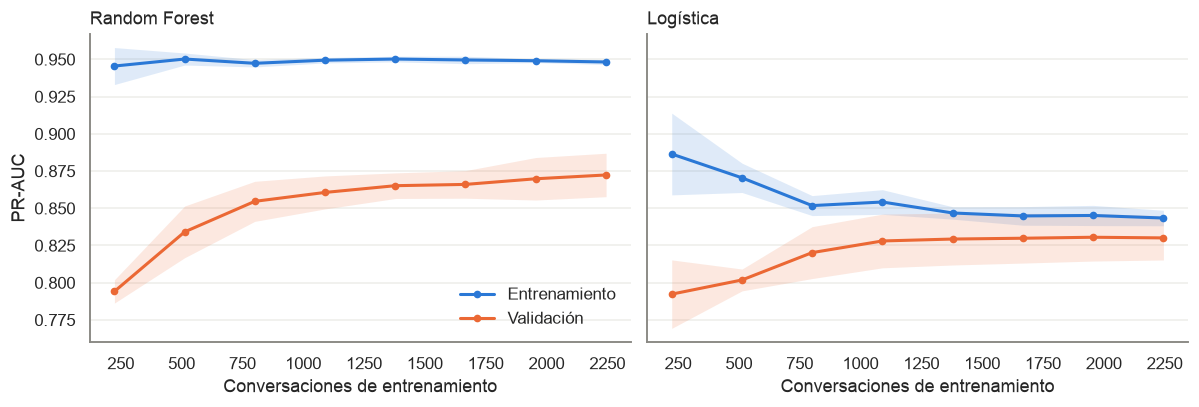

In [27]:
Xtr_f = build_features(tr, DROP)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (nombre, est) in zip(axs, [("Random Forest", make_rf(**best_params)),
                                    ("Logística", mejores[("sin ai_chars_mean", "Logística")])]):
    sizes, tr_sc, va_sc = learning_curve(est, Xtr_f, y_tr, groups=tr.cliente, cv=cv, scoring="average_precision",
                                         train_sizes=np.linspace(0.1, 1, 8), n_jobs=-1, shuffle=True, random_state=RNG)
    for sc, c, lab in [(tr_sc, C0, "Entrenamiento"), (va_sc, C1, "Validación")]:
        ax.plot(sizes, sc.mean(1), color=c, lw=2, marker="o", ms=4, label=lab)
        ax.fill_between(sizes, sc.mean(1) - sc.std(1), sc.mean(1) + sc.std(1), color=c, alpha=.15, lw=0)
    ax.set_title(nombre, loc="left"); ax.set_xlabel("Conversaciones de entrenamiento"); ax.grid(axis="y", color="#eeede9")
    print(f"{nombre}: brecha final entrenamiento − validación = {tr_sc.mean(1)[-1] - va_sc.mean(1)[-1]:.3f}, "
          f"validación {va_sc.mean(1)[0]:.3f} → {va_sc.mean(1)[-1]:.3f}")
axs[0].set_ylabel("PR-AUC"); axs[0].legend(frameon=False)
fig.tight_layout(); save(fig, "11_curvas_aprendizaje"); plt.show()

- **Random Forest:** hay una brecha entre entrenamiento y validación, esperable en un bosque con
  hojas pequeñas. Pero la validación **sigue subiendo** con más datos y su variación entre pliegues
  es baja: no hay un sobreajuste que dañe la generalización, y más datos (más meses, más empresas)
  deberían seguir mejorando el modelo. Esto respalda el reentrenamiento periódico de la sección 3.9.
- **Logística:** las dos curvas casi se tocan. El modelo está limitado por su forma lineal, no por
  falta de datos.

## 3.b Auditoría de fuga de información y sobreajuste

Una métrica alta no sirve si el modelo vio, directa o indirectamente, el desenlace. Se revisan las
vías posibles de fuga, cada una con una prueba:

1. **Historial del cliente** (`prior_*`): ¿cuenta solo conversaciones anteriores y sus etiquetas, o
   incluye la propia?
2. **Historial del mismo día:** una conversación anterior del mismo día podría no tener aún su
   desenlace cuando empieza la actual. Se reconstruye el historial **solo con días anteriores** y se
   compara.
3. **Etiquetas barajadas:** si el modelo encuentra señal con etiquetas al azar, hay fuga por la
   estructura de los datos.
4. **Una sola variable:** ninguna variable debería separar casi perfectamente por sí sola.
5. **Filas repetidas** entre entrenamiento y prueba.
6. **Validación adversaria:** ¿qué tan distinto es octubre del entrenamiento? Explica la brecha
   entre la validación cruzada y la prueba.

In [28]:
# 1. History counts only earlier conversations of the same customer.
g = df.sort_values(["cliente", "prior_conversations"]).copy()
g["d_conv"] = g.groupby("cliente").prior_conversations.diff()
g["d_hum"] = g.groupby("cliente").prior_needed_human.diff()
g["y_prev"] = g.groupby("cliente")[TARGET].shift()
paso = g[g.d_conv == 1]
print("1. Primera conversación de cada cliente con historial 0:",
      f"{(g.groupby('cliente').head(1).prior_conversations == 0).mean():.0%}")
print("   Al pasar a la siguiente conversación, prior_needed_human sube exactamente la etiqueta de la anterior:",
      f"{(paso.d_hum == paso.y_prev).mean():.0%} de {len(paso):,} pares")
print("   Conversaciones cuyo historial incluye una fecha posterior:", int((g.groupby('cliente').fecha.diff().dt.days < 0).sum()))

# 2. Conservative history: only strictly earlier days.
dia = (df.groupby(["cliente", "fecha"]).agg(n=(TARGET, "size"), h=(TARGET, "sum")).reset_index()
         .sort_values(["cliente", "fecha"]))
dia["prev_n"] = dia.groupby("cliente").n.cumsum() - dia.n
dia["prev_h"] = dia.groupby("cliente").h.cumsum() - dia.h
def con_historial_de_dias_anteriores(d):
    d = d.merge(dia[["cliente", "fecha", "prev_n", "prev_h"]], on=["cliente", "fecha"], how="left")
    return d.assign(prior_conversations=d.prev_n, prior_needed_human=d.prev_h).drop(columns=["prev_n", "prev_h"])
def evaluar(train, test, drop=DROP, y_train=None):
    m = make_rf(**best_params).fit(build_features(train, drop), train[TARGET] if y_train is None else y_train)
    p = m.predict_proba(build_features(test, drop))[:, 1]
    return m, p, roc_auc_score(test[TARGET], p), average_precision_score(test[TARGET], p)

m_base, p_base, roc0, pr0 = evaluar(tr, te)
tr_c, te_c = con_historial_de_dias_anteriores(tr), con_historial_de_dias_anteriores(te)
_, p_c, roc_c, pr_c = evaluar(tr_c, te_c)
print(f"\n2. Octubre, historial original:              ROC-AUC {roc0:.3f} · PR-AUC {pr0:.3f}")
print(f"   Octubre, historial solo de días anteriores: ROC-AUC {roc_c:.3f} · PR-AUC {pr_c:.3f}")
_, _, roc_h, pr_h = evaluar(tr, te, DROP + ("prior_conversations", "prior_needed_human", "prior_human_rate", "has_history"))
print(f"   Octubre, sin ninguna variable de historial: ROC-AUC {roc_h:.3f} · PR-AUC {pr_h:.3f}")
sin_hist = (te.prior_conversations == 0).values
print(f"   Modelo elegido en conversaciones de octubre sin historial (n={sin_hist.sum():,}): "
      f"ROC-AUC {roc_auc_score(y_te[sin_hist], p_base[sin_hist]):.3f}")

# 3. Shuffled labels.
rng = np.random.default_rng(0)
barajado = [evaluar(tr, te, y_train=rng.permutation(y_tr))[2] for _ in range(5)]
print(f"\n3. Etiquetas barajadas (5 repeticiones): ROC-AUC en octubre {np.mean(barajado):.3f} ± {np.std(barajado):.3f}")

# 4. Single features.
X_te_f = build_features(te, DROP)
una = {c: roc_auc_score(y_te, X_te_f[c].fillna(X_te_f[c].median())) for c in X_te_f if X_te_f[c].nunique() > 1}
una = pd.Series({c: max(a, 1 - a) for c, a in una.items()}).sort_values(ascending=False)
print("\n4. Mejores variables solas en octubre (ROC-AUC, sin importar la dirección):", una.head(5).round(3).to_dict())

# 5. Identical rows.
crudas = [c for c in df.columns if c not in ("empresa", "cliente", "fecha", "mes", TARGET)]
print("\n5. Filas de octubre idénticas a una de entrenamiento:", len(te.merge(tr[crudas].drop_duplicates(), on=crudas)))

# 6. Adversarial validation and the train / CV / test gap.
from sklearn.model_selection import cross_val_predict, StratifiedKFold
Xa = pd.concat([build_features(tr, DROP), X_te_f]); ya = np.r_[np.zeros(len(tr)), np.ones(len(te))]
pa = cross_val_predict(make_rf(max_depth=6), Xa, ya, cv=StratifiedKFold(5, shuffle=True, random_state=RNG),
                       method="predict_proba")[:, 1]
print(f"\n6. Validación adversaria (distinguir jul–sep de octubre): ROC-AUC {roc_auc_score(ya, pa):.3f}")
print(f"   Modelo elegido: ROC-AUC en su propio entrenamiento {roc_auc_score(y_tr, m_base.predict_proba(build_features(tr, DROP))[:, 1]):.3f}"
      f" · octubre {roc0:.3f}")

1. Primera conversación de cada cliente con historial 0: 100%
   Al pasar a la siguiente conversación, prior_needed_human sube exactamente la etiqueta de la anterior: 100% de 58,441 pares
   Conversaciones cuyo historial incluye una fecha posterior: 0



2. Octubre, historial original:              ROC-AUC 0.786 · PR-AUC 0.771
   Octubre, historial solo de días anteriores: ROC-AUC 0.786 · PR-AUC 0.771


   Octubre, sin ninguna variable de historial: ROC-AUC 0.768 · PR-AUC 0.731
   Modelo elegido en conversaciones de octubre sin historial (n=1,353): ROC-AUC 0.719



3. Etiquetas barajadas (5 repeticiones): ROC-AUC en octubre 0.481 ± 0.059

4. Mejores variables solas en octubre (ROC-AUC, sin importar la dirección): {'prior_conversations': 0.648, 'log_cust_chars_mean': 0.63, 'log_cust_chars_max': 0.625, 'has_history': 0.624, 'log_first_ai_reply_s': 0.619}

5. Filas de octubre idénticas a una de entrenamiento: 0



6. Validación adversaria (distinguir jul–sep de octubre): ROC-AUC 0.861
   Modelo elegido: ROC-AUC en su propio entrenamiento 0.904 · octubre 0.786


**Lectura.**

- **El historial no filtra el desenlace.** Cada conversación cuenta solo las anteriores del mismo
  cliente, y la etiqueta propia nunca entra (la suma sube exactamente con la etiqueta de la anterior,
  en el 100 % de los pares). Reconstruirlo solo con días anteriores, el caso en que el desenlace previo
  seguro ya se conocía, **no cambia las métricas de octubre**. En producción el historial se calcula
  igual: solo con conversaciones cerradas antes de la actual (ver `model_card.md`).
- **El historial aporta, pero el modelo no depende de él.** Sin esas variables, el PR-AUC de octubre
  baja unos 0,04, y en las conversaciones sin ningún historial el modelo sigue muy por encima del azar.
- **Con etiquetas barajadas el modelo cae al azar** (ROC-AUC ≈ 0,5): la señal viene de la relación
  real entre las variables y el desenlace, no de la estructura de los datos.
- **Ninguna variable sola pasa de ≈ 0,65.** No hay un "atajo" que delate la etiqueta.
- **No hay filas repetidas** entre entrenamiento y prueba.
- **Octubre es muy distinto del entrenamiento** (validación adversaria ≈ 0,86), sobre todo por qué
  empresas escribieron. Eso explica por qué la validación cruzada (≈ 0,87 de PR-AUC) da más que
  octubre (≈ 0,77), y por qué la cifra que se reporta es la de octubre y no la de validación cruzada.
- **Sobreajuste:** la brecha entre entrenamiento y octubre es la esperable en un bosque. Las curvas
  de aprendizaje (sección 3) muestran que la validación sigue subiendo con más datos, y el modelo
  elegido es el mejor en los tres esquemas de evaluación, no solo en el que guió la búsqueda.

**Fuera del alcance de estos datos.** Hay una vía que solo se puede revisar en la base de producción:
que el agente haya transferido a una persona *dentro* de los primeros 4 mensajes sin que esa persona
haya escrito aún. El extractor corta la ventana en el primer mensaje humano, pero no en la hora de la
transferencia. Queda como verificación pendiente en `docs/documento_tecnico.md`.

## 4. Calibración y punto de corte

Se usa el Random Forest elegido con **calibración isotónica**, ajustada con pliegues agrupados por
cliente. Para elegir el punto de corte sin mirar octubre, se generan predicciones **fuera de
pliegue** en el entrenamiento (validación cruzada anidada: cada conversación se predice con un
modelo, y una calibración, que no la vio).

Se definen dos umbrales sobre esa probabilidad:
- **Alerta (rojo):** el más alto que todavía detecta **al menos el 80 %** de los casos que van a
  necesitar persona. Entre los que cumplen esa meta, es el de mayor precisión.
- **Vigilar (amarillo):** el que detecta el 95 %.

¿Por qué 80 %? Dejar pasar un caso que se complica cuesta más que una alerta de más, pero
alertar casi todo cansa al asesor. La meta es un parámetro de negocio y se puede mover.

In [29]:
rf_base = make_rf(**best_params)
oof = np.zeros(len(tr))
for a, b in group_splits(Xtr_f, y_tr, tr.cliente.values, seed=1):
    cal = calibrated(rf_base, Xtr_f.iloc[a], y_tr[a], tr.cliente.values[a])
    oof[b] = cal.predict_proba(Xtr_f.iloc[b])[:, 1]
T_ALERTA, T_VIGILAR = threshold_for_recall(y_tr, oof, 0.80), threshold_for_recall(y_tr, oof, 0.95)
print(f"Fuera de pliegue (jul–sep): PR-AUC {average_precision_score(y_tr, oof):.3f} | Brier {brier_score_loss(y_tr, oof):.3f}")
print(f"Umbral de alerta {T_ALERTA:.3f} → recall {recall_score(y_tr, oof >= T_ALERTA):.2f}, precisión {precision_score(y_tr, oof >= T_ALERTA):.2f}")
print(f"Umbral de vigilancia {T_VIGILAR:.3f} → recall {recall_score(y_tr, oof >= T_VIGILAR):.2f}, precisión {precision_score(y_tr, oof >= T_VIGILAR):.2f}")

modelo_cal = calibrated(rf_base, Xtr_f, y_tr, tr.cliente.values)       # final model for the October test
rf_sin_cal = clone(rf_base).fit(Xtr_f, y_tr)
Xte_f = build_features(te, DROP)
p_cal, p_raw = modelo_cal.predict_proba(Xte_f)[:, 1], rf_sin_cal.predict_proba(Xte_f)[:, 1]
PRIOR_TR = y_tr.mean()

Fuera de pliegue (jul–sep): PR-AUC 0.864 | Brier 0.179
Umbral de alerta 0.543 → recall 0.80, precisión 0.78
Umbral de vigilancia 0.373 → recall 0.95, precisión 0.71


### Cambio en la tasa base de octubre: ¿hay que corregir la probabilidad?

En el EDA, la proporción de positivos cae de 65 % (entrenamiento) a 44 % (octubre). Hay dos
explicaciones posibles, y cada una pide algo distinto:

- **Cambio de proporción (*label shift*):** cambia cuántos casos necesitan persona, pero cada tipo
  de conversación se ve igual que antes. Hay que corregir la probabilidad.
- **Cambio de mezcla (*covariate shift*):** cambia qué empresas y qué conversaciones llegan, pero
  para una conversación dada la probabilidad es la misma. El modelo ya lo absorbe, porque ve las
  variables que distinguen a cada operación, y **no hay que corregir nada**.

Si fuera *label shift*, la corrección es la regla de Bayes:

$$p' = \frac{\frac{\pi'}{\pi}\,p}{\frac{\pi'}{\pi}\,p + \frac{1-\pi'}{1-\pi}\,(1-p)}$$

y la nueva tasa $\pi'$ se puede **estimar sin etiquetas** con el algoritmo EM de Saerens et al.
(2002), usando solo las predicciones del mes. Se prueban las dos hipótesis.

Tasa base: entrenamiento 0.649 | estimada por EM sin etiquetas 0.126 | real de octubre 0.445
                                    Brier  riesgo medio predicho
Random Forest sin calibrar          0.188                  0.379
Isotónica (tasa de entrenamiento)   0.184                  0.465
Isotónica + EM (sin etiquetas)      0.301                  0.126
Isotónica + tasa real (referencia)  0.199                  0.324


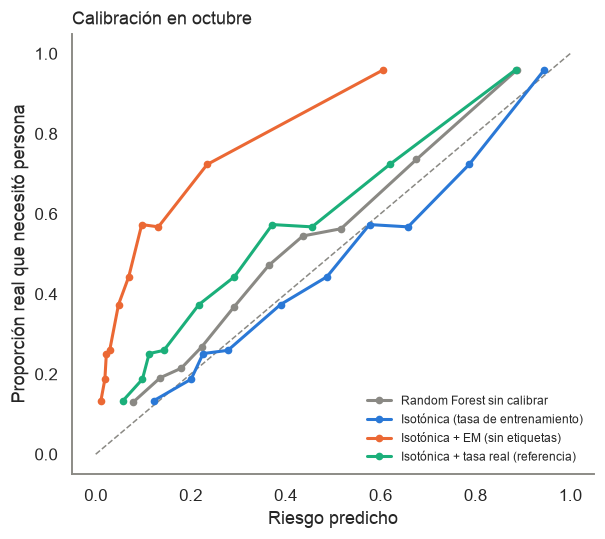

In [30]:
pi_em = estimate_prior_em(p_cal, PRIOR_TR)
p_em, p_oracle = shift_prior(p_cal, PRIOR_TR, pi_em), shift_prior(p_cal, PRIOR_TR, y_te.mean())
print(f"Tasa base: entrenamiento {PRIOR_TR:.3f} | estimada por EM sin etiquetas {pi_em:.3f} | real de octubre {y_te.mean():.3f}")
cal_tab = pd.DataFrame({
    "Random Forest sin calibrar": p_raw, "Isotónica (tasa de entrenamiento)": p_cal,
    "Isotónica + EM (sin etiquetas)": p_em, "Isotónica + tasa real (referencia)": p_oracle})
print(pd.DataFrame({"Brier": cal_tab.apply(lambda p: brier_score_loss(y_te, p)),
                    "riesgo medio predicho": cal_tab.mean()}).round(3))

fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
for (lab, p), c in zip(cal_tab.items(), [MUTED, C0, C1, C2]):
    fy, fx = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax.plot(fx, fy, marker="o", ms=4, lw=2, color=c, label=lab)
ax.set_xlabel("Riesgo predicho"); ax.set_ylabel("Proporción real que necesitó persona")
ax.set_title("Calibración en octubre", loc="left"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "12_calibracion"); plt.show()

**Resultado: es un cambio de mezcla, no de proporción.**

- **La calibración isotónica sin corregir ya acierta en octubre:** predice un riesgo medio de
  ≈ 46 % cuando el real fue 44 %, y tiene el mejor Brier. El modelo siguió el cambio porque
  reconoce el tipo de operación de cada conversación.
- **La corrección EM falla:** estima una tasa base de ≈ 13 % y empeora mucho la calibración. Ni
  siquiera la tasa real de octubre mejora el resultado. Ambas parten de un supuesto falso (que
  cada conversación se ve igual y solo cambió la proporción) y terminan corrigiendo dos veces.
- El Random Forest sin calibrar, entrenado con pesos balanceados, sí produce probabilidades
  sesgadas; la isotónica las arregla.

**Decisión:** se despliega la probabilidad isotónica **sin corrección por tasa base**. El monitoreo
vigila la calibración **por empresa**, porque la corrección solo se justifica si dentro de una misma
empresa cambia la proporción de casos (por ejemplo, si cambian su operación). Esta hipótesis
quedó escrita en el EDA como riesgo, y aquí se refuta con datos.

## 5. Resultado en octubre con el punto de corte

,ROC-AUC,PR-AUC,azar PR,recall,precisión,% alertado
Octubre,0.786,0.770,0.445,0.623,0.707,0.392
"Octubre, clientes nuevos",0.736,0.784,0.543,0.663,0.700,0.514


Calibración por empresa (riesgo medio predicho vs real):


,n,predicho,real
empresa,,,
E01,1010,0.28,0.22
E12,464,0.59,0.56
E06,427,0.44,0.34
E10,179,0.56,0.84
E07,169,0.91,0.99
E04,109,0.54,0.61
E08,60,0.87,0.95
E02,30,0.94,1.00
E11,17,0.59,0.06


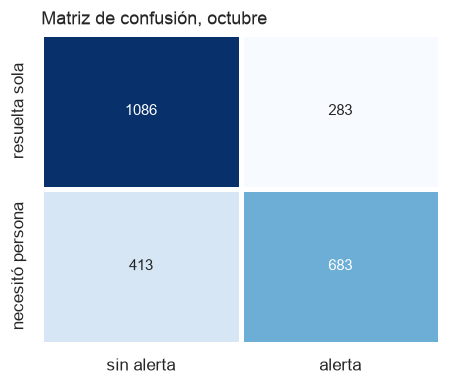

In [31]:
alerta = p_cal >= T_ALERTA
tn, fp, fn, tp = confusion_matrix(y_te, alerta).ravel()
def bloque(y, p, a):
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p), "azar PR": y.mean(),
            "recall": recall_score(y, a), "precisión": precision_score(y, a), "% alertado": a.mean()}
res_oct = pd.DataFrame({"Octubre": bloque(y_te, p_cal, alerta),
                        "Octubre, clientes nuevos": bloque(y_te[new_cust], p_cal[new_cust], alerta[new_cust])}).T.round(3)
display(res_oct)
print("Calibración por empresa (riesgo medio predicho vs real):")
display(te.assign(p=p_cal).groupby("empresa").agg(n=("p", "size"), predicho=("p", "mean"), real=(TARGET, "mean"))
        .sort_values("n", ascending=False).round(2))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
sns.heatmap([[tn, fp], [fn, tp]], annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["sin alerta", "alerta"], yticklabels=["resuelta sola", "necesitó persona"], ax=ax)
ax.set_title("Matriz de confusión, octubre", loc="left"); fig.tight_layout(); save(fig, "13_confusion"); plt.show()

**El recall de octubre (≈ 0,62) no llega a la meta de 0,80 que se cumplía en validación.** La
razón es el mismo cambio de mezcla. En el entrenamiento, el recall global de 0,80 lo sostenían las
empresas que escalan mucho; en las que escalan poco (como E01), el recall con ese umbral ya era
≈ 0,3. En octubre, E01 pasa a ser el 40 % de las conversaciones y arrastra el promedio.

Bajo *label shift*, el recall con un umbral fijo no cambiaría; aquí sí cambia, y es otra señal de
que el cambio es de mezcla. Se compara la alternativa de **un umbral por empresa**, elegido con las
predicciones fuera de pliegue del entrenamiento, para empresas con al menos 20 positivos y 10
negativos, y el global como respaldo para las demás.

### 3.c Verificación en producción: escalaciones dentro de la ventana y anticipación

El extractor corta la ventana en el primer mensaje **humano**, pero no en una **escalación**. Si el
agente escaló dentro de los primeros 4 mensajes, los mensajes posteriores (por ejemplo, el aviso de
transferencia) estarían en la ventana y filtrarían la etiqueta. `sql/timing.sql` (solo lectura, sin
identificadores ni texto) midió, para cada conversación de julio a octubre de 2026, cuántos mensajes
de la ventana son posteriores a la escalación (`escalation_events`; `handoff_at` nunca se llena) y
los segundos entre el 4.º mensaje y cada desenlace. Las filas se emparejan con el CSV por sus
propias variables.

In [32]:
from timing import load_timing, attach, margin_summary
timing = load_timing(str(ROOT / "data" / "timing" / "*.csv"))
todo = attach(load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv"), timing)
jo = todo.fecha >= "2026-07-01"
print(f"Emparejadas (jul–oct): {todo.matched[jo].mean():.1%} de {jo.sum():,} filas")
print("Conversaciones con mensajes de la ventana posteriores a una escalación:")
print(todo[jo].assign(grupo=np.where(todo.empresa[jo] == DOMINANT, f"{DOMINANT} (excluida)", "dataset principal"))
      .groupby("grupo").agg(filas=("esc_in_window", "size"), escaladas_en_ventana=("esc_in_window", "sum")).to_string())

esc_tr = attach(tr, timing).esc_in_window.values
esc_te = attach(te, timing).esc_in_window.values
keep = ~esc_tr
modelo_limpio = calibrated(rf_base, Xtr_f[keep], y_tr[keep], tr.cliente.values[keep])
p_limpio = modelo_limpio.predict_proba(Xte_f)[:, 1]
antes_despues = pd.DataFrame({
    "Octubre (como se reportó)": bloque(y_te, p_cal, p_cal >= T_ALERTA),
    "Octubre sin filas escaladas": bloque(y_te[~esc_te], p_cal[~esc_te], p_cal[~esc_te] >= T_ALERTA),
    "Reentrenado sin filas escaladas": bloque(y_te[~esc_te], p_limpio[~esc_te], p_limpio[~esc_te] >= T_ALERTA),
}).T
vol = (p_cal >= T_ALERTA).mean()
antes_despues["recall a igual volumen de alertas"] = [
    y[np.argsort(-p)[:int(round(vol * len(p)))]].sum() / y.sum()
    for y, p in [(y_te, p_cal), (y_te[~esc_te], p_cal[~esc_te]), (y_te[~esc_te], p_limpio[~esc_te])]]
antes_despues = antes_despues.round(3)
print(f"Filas excluidas: {esc_tr.sum()} de entrenamiento, {esc_te.sum()} de octubre")
display(antes_despues)

Emparejadas (jul–oct): 99.9% de 62,162 filas
Conversaciones con mensajes de la ventana posteriores a una escalación:
                   filas  escaladas_en_ventana
grupo                                         
E09 (excluida)     57517                  1603
dataset principal   4645                     1


Filas excluidas: 1 de entrenamiento, 0 de octubre


,ROC-AUC,PR-AUC,azar PR,recall,precisión,% alertado,recall a igual volumen de alertas
Octubre (como se reportó),0.786,0.770,0.445,0.623,0.707,0.392,0.623
Octubre sin filas escaladas,0.786,0.770,0.445,0.623,0.707,0.392,0.623
Reentrenado sin filas escaladas,0.783,0.771,0.445,0.579,0.709,0.363,0.620


**Resultado.** Las conversaciones escaladas dentro de la ventana son casi todas de la empresa
dominante, que ya estaba fuera del dataset principal. En el dataset principal hay **una sola** (en
agosto, y no necesitó persona) y ninguna en octubre, así que las métricas de octubre no cambian:
**no hay fuga por escalación**. Al reentrenar sin esa fila, el orden casi no cambia (ROC-AUC y PR-AUC se mueven en el tercer decimal) y el recall a igual volumen de alertas tampoco. El recall con el umbral fijo sí se mueve unos puntos porque la isotónica es una función escalonada y los escalones se corren al cambiar los datos; por eso el umbral se vuelve a elegir en cada reentrenamiento (3.9). Las de la empresa dominante, además, son una cota superior: si la
escalación no trae la sesión, la consulta la busca por chat en los 7 días siguientes y puede tomar
la de otra conversación.

**Anticipación.** Para las conversaciones de octubre que necesitaron persona, minutos entre la
predicción (4.º mensaje) y el desenlace, según el nivel que les dio el modelo:

In [33]:
te_t = attach(te, timing).assign(p=p_cal)
pos = te_t[te_t[TARGET] == 1]
filas = {}
for nivel, mask in [("Todas las que necesitaron persona", pos.p >= 0), ("Marcadas en rojo (alerta)", pos.p >= T_ALERTA),
                    ("Rojo o amarillo (vigilar)", pos.p >= T_VIGILAR)]:
    for desenlace, col in [("primer mensaje humano", "human_rel_s"), ("escalación", "esc_rel_s")]:
        filas[(nivel, desenlace)] = margin_summary(pos.loc[mask, col])
anticipacion = pd.DataFrame(filas).T
print(anticipacion.round(3).to_string())

                                                              n  mediana_min  p25_min  p75_min   p90_min  % antes  % ≥1 min  % ≥5 min
Todas las que necesitaron persona primer mensaje humano  1096.0       28.875    6.974  363.762  1343.560      1.0     0.958     0.831
                                  escalación               29.0        0.042    0.037    0.055     1.923      1.0     0.103     0.103
Marcadas en rojo (alerta)         primer mensaje humano   683.0       26.908    6.000  519.940  1436.108      1.0     0.944     0.802
                                  escalación               29.0        0.042    0.037    0.055     1.923      1.0     0.103     0.103
Rojo o amarillo (vigilar)         primer mensaje humano   868.0       32.308    6.517  610.500  1509.681      1.0     0.950     0.819
                                  escalación               29.0        0.042    0.037    0.055     1.923      1.0     0.103     0.103


En octubre, **todas** las alertas llegan antes de que escriba una persona, porque la ventana solo
admite mensajes anteriores a ella; el margen es lo que se gana. En los casos marcados en rojo, la
mediana es de 27 minutos (p25 6 min), y en 8 de cada 10 hay 5 minutos o más para reaccionar. La cola es
larga (p75 de horas), porque muchas conversaciones esperan fuera del horario del equipo. Las
escalaciones automáticas son pocas fuera de la empresa dominante (29 en octubre, todas marcadas en rojo) y ocurren
segundos después del 4.º mensaje: ahí la alerta casi no adelanta nada, porque el propio agente ya escala. Su valor está
en el resto, las que una persona toma por iniciativa propia.

,recall,precisión,% alertado
Umbral global,0.623,0.707,0.392
Umbral por empresa,0.806,0.469,0.763


A posteriori, sobre la curva global de octubre: con recall 0,80 la precisión sería 0.63


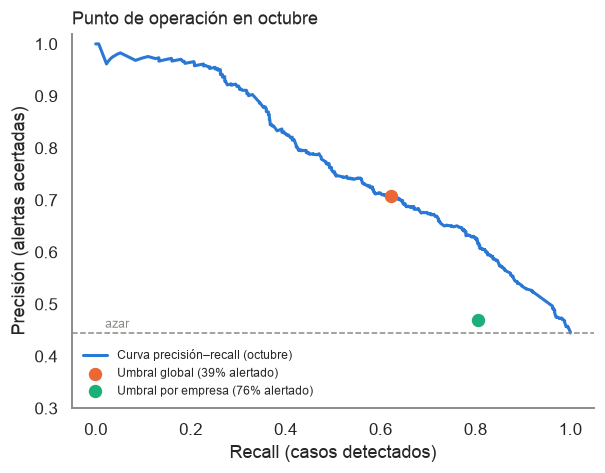

In [34]:
th_emp = {}
for e, g in tr.assign(o=oof).groupby("empresa"):
    if g[TARGET].sum() >= 20 and (1 - g[TARGET]).sum() >= 10:
        th_emp[e] = threshold_for_recall(g[TARGET].values, g.o.values, 0.80)
t_emp = te.empresa.map(th_emp).fillna(T_ALERTA).values
pol = pd.DataFrame({nombre: {"recall": recall_score(y_te, a), "precisión": precision_score(y_te, a), "% alertado": a.mean()}
                    for nombre, a in [("Umbral global", p_cal >= T_ALERTA), ("Umbral por empresa", p_cal >= t_emp)]}).T
display(pol.round(3))
prec_c, rec_c, _ = precision_recall_curve(y_te, p_cal); p_at_80 = prec_c[np.argmin(np.abs(rec_c - 0.80))]
print(f"A posteriori, sobre la curva global de octubre: con recall 0,80 la precisión sería {p_at_80:.2f}")

prec_c, rec_c, _ = precision_recall_curve(y_te, p_cal)
fig, ax = plt.subplots(figsize=(5.6, 4.4))
ax.plot(rec_c, prec_c, color=C0, lw=2, label="Curva precisión–recall (octubre)")
ax.axhline(y_te.mean(), color=MUTED, ls="--", lw=1); ax.text(0.02, y_te.mean() + 0.01, "azar", color=MUTED, fontsize=8)
for (nombre, r), c in zip(pol.iterrows(), [C1, C2]):
    ax.scatter(r["recall"], r["precisión"], color=c, s=60, zorder=3, label=f"{nombre} ({r['% alertado']:.0%} alertado)")
ax.set_xlabel("Recall (casos detectados)"); ax.set_ylabel("Precisión (alertas acertadas)"); ax.set_ylim(0.3, 1.02)
ax.set_title("Punto de operación en octubre", loc="left"); ax.legend(frameon=False, fontsize=8, loc="lower left")
fig.tight_layout(); save(fig, "13b_politicas_umbral"); plt.show()

Con un umbral por empresa se recupera el recall de 0,80, pero alertando 3 de cada 4
conversaciones con precisión menor a 0,5: en E01, por ejemplo, el umbral queda tan bajo que casi
todo se alerta. Además, ese punto queda **por debajo de la curva global**: bajar el único umbral
global hasta recall 0,80 daría más precisión (≈ 0,6). Con estos datos, los umbrales por empresa no
convienen; su estimación con pocos casos por empresa es ruidosa.

**Decisión de despliegue:**
- **Semáforo con el umbral global.** En octubre detecta 6 de cada 10 casos con 7 de cada 10
  alertas acertadas, y sirve sobre todo para **ordenar la cola** (ver el lift abajo).
- Si el negocio necesita más recall, **se baja el umbral global**, reelegido con los datos del mes
  más reciente durante el monitoreo (3.9), en lugar de fijar umbrales por empresa.

### Métricas de negocio

La alerta se da al **cuarto mensaje**, y por construcción esos 4 mensajes son anteriores a
cualquier intervención humana. Así que cada caso detectado se detecta **antes** de que una persona
del equipo entre a la conversación.

*Limitación honesta:* el conjunto anonimizado no trae cuántos mensajes o minutos después entró la
persona, así que aquí no se puede medir la anticipación exacta. Se agrega como métrica del
monitoreo en producción: el tiempo entre la alerta y el primer mensaje humano.

In [35]:
def top_k(y, p, frac):
    k = int(round(len(p) * frac)); idx = np.argsort(-p)[:k]; return y[idx].mean(), y[idx].sum() / y.sum()
neg = pd.DataFrame({
    "Conversaciones de octubre": len(y_te),
    "Necesitaron persona": int(y_te.sum()),
    "Detectadas al mensaje 4": int(tp),
    "No detectadas": int(fn),
    "Alertas por cada 100 conversaciones": round(100 * alerta.mean(), 1),
    "Alertas acertadas por cada 10": round(10 * tp / (tp + fp), 1),
    "Acertadas por cada 10 si se alertara al azar": round(10 * y_te.mean(), 1),
}, index=["valor"]).T
display(neg)
rows = []
for f in [0.1, 0.2, 0.3]:
    prec, rec = top_k(y_te, p_cal, f)
    rows.append({"revisar primero el": f"{f:.0%} más riesgoso", "precisión": prec, "captura de casos": rec,
                 "lift vs azar": prec / y_te.mean()})
pd.DataFrame(rows).set_index("revisar primero el").round(2)

,valor
Conversaciones de octubre,2465.0
Necesitaron persona,1096.0
Detectadas al mensaje 4,683.0
No detectadas,413.0
Alertas por cada 100 conversaciones,39.2
Alertas acertadas por cada 10,7.1
Acertadas por cada 10 si se alertara al azar,4.4


,precisión,captura de casos,lift vs azar
revisar primero el,,,
10% más riesgoso,0.96,0.22,2.16
20% más riesgoso,0.84,0.38,1.89
30% más riesgoso,0.75,0.51,1.68


### Por empresa
Calidad del orden **dentro** de cada empresa en octubre, y comportamiento del umbral global.

In [36]:
filas = []
for e, g in te.assign(p=p_cal, a=alerta).groupby("empresa"):
    y = g[TARGET].values
    filas.append({"empresa": e, "n": len(g), "% positivos": y.mean(),
                  "ROC-AUC": roc_auc_score(y, g.p) if 0 < y.sum() < len(y) else np.nan,
                  "recall": recall_score(y, g.a) if y.sum() else np.nan,
                  "precisión": precision_score(y, g.a, zero_division=0) if g.a.sum() else np.nan,
                  "% alertado": g.a.mean()})
por_emp = pd.DataFrame(filas).set_index("empresa").sort_values("n", ascending=False)
por_emp.round(2)

,n,% positivos,ROC-AUC,recall,precisión,% alertado
empresa,,,,,,
E01,1010,0.22,0.67,0.30,0.56,0.12
E12,464,0.56,0.58,0.69,0.59,0.65
E06,427,0.34,0.59,0.44,0.47,0.32
E10,179,0.84,0.73,0.58,0.95,0.51
E07,169,0.99,0.74,0.99,0.99,0.99
E04,109,0.61,0.62,0.62,0.71,0.53
E08,60,0.95,0.91,0.95,0.98,0.92
E02,30,1.00,NaN,1.00,1.00,1.00
E11,17,0.06,0.12,0.00,0.00,0.59


- El orden dentro de cada empresa es moderado: AUC entre 0,58 y 0,74 en las empresas con
  suficientes casos, y 0,91 en E08. Buena parte de lo que el modelo sabe es **qué tipo de operación
  tiene cada empresa**, y dentro de ella la señal más fuerte es el **historial del cliente**.
- E11 (17 conversaciones, 1 positiva) y E02 (todas positivas) no permiten medir el orden.
- Con un solo umbral global, las empresas que escalan poco reciben pocas alertas (E01: 12 %) y las
  que escalan casi siempre lo reciben casi todo (E07: 99 %). Para esas últimas la alerta no aporta;
  lo útil es el orden dentro de la cola.

## 6. Explicabilidad con SHAP

SHAP reparte la predicción de cada conversación entre sus variables (valores de Shapley).
Se explica el Random Forest base sin calibrar; la calibración es monótona, así que el orden y la
dirección de los efectos se conservan.

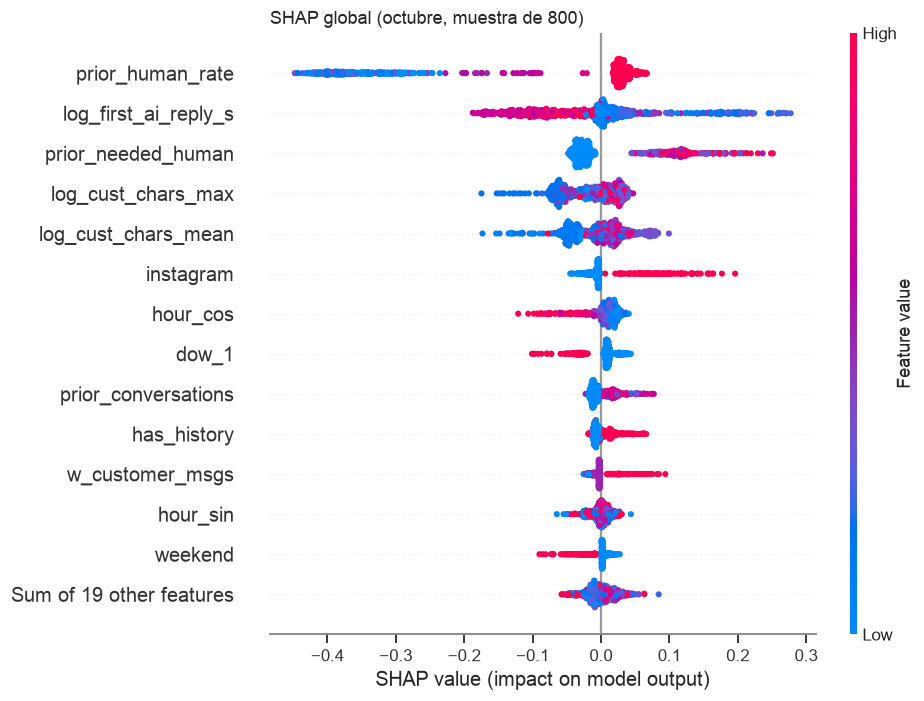

prior_human_rate        0.1483
log_first_ai_reply_s    0.0675
prior_needed_human      0.0565
log_cust_chars_max      0.0343
log_cust_chars_mean     0.0315
instagram               0.0194
hour_cos                0.0168
dow_1                   0.0163
prior_conversations     0.0135
has_history             0.0105
w_customer_msgs         0.0103
hour_sin                0.0096
dtype: float64

In [37]:
sample = te.sample(800, random_state=RNG)
X_s = rf_sin_cal[:-1].transform(build_features(sample, DROP))
expl = shap.TreeExplainer(rf_sin_cal[-1])(X_s)
sv = expl[:, :, 1]
plt.figure(); shap.plots.beeswarm(sv, max_display=14, show=False)
plt.title("SHAP global (octubre, muestra de 800)", loc="left"); save(plt.gcf(), "14_shap_beeswarm"); plt.show()
imp_shap = pd.Series(np.abs(sv.values).mean(0), index=X_s.columns).sort_values(ascending=False)
imp_shap.head(12).round(4)

**Lectura del gráfico.** Cada punto es una conversación. A la derecha, la variable sube el riesgo;
a la izquierda, lo baja. El color es el valor de la variable (rojo alto, azul bajo).

- **El historial del cliente domina.** Si sus conversaciones pasadas se resolvieron solas
  (`prior_human_rate` baja), el riesgo cae mucho; si necesitaron persona, sube. Una vez conocida esa
  proporción, tener más historial suma un poco de riesgo.
- **Tiempo de primera respuesta:** respuestas automáticas lentas se asocian a *menos* riesgo. No es
  causal: refleja qué tipo de automatización usa cada empresa (flujos con espera frente a IA
  inmediata). Es otra huella parcial de la operación.
- **Largo de los mensajes del cliente:** mensajes muy cortos (tocar un botón, un saludo, un «sí»)
  bajan el riesgo; los largos lo suben un poco.
- **Instagram sube el riesgo; lunes y fines de semana lo bajan.** Son efectos pequeños y, en parte,
  de la mezcla de empresas por canal y día.

### `ai_chars_mean` vista con SHAP: una huella de la empresa
Con el modelo que sí la usa, se compara su valor SHAP por empresa.

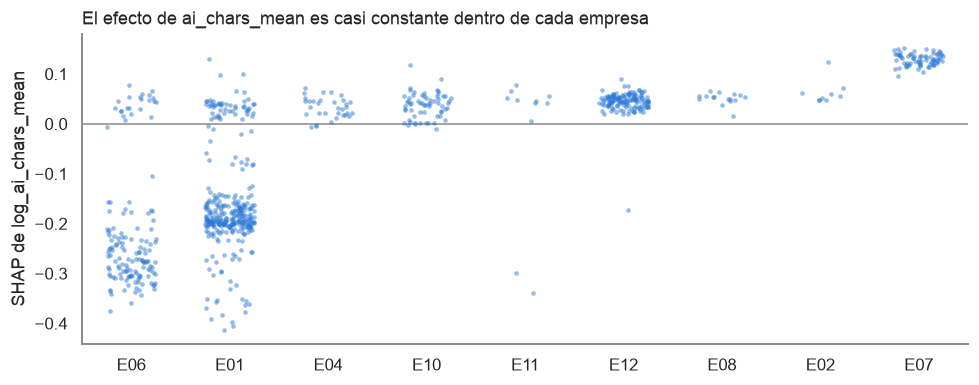

Parte de la varianza del SHAP de ai_chars_mean explicada por la empresa: 67%


In [38]:
rf_con = mejores[("con ai_chars_mean", "Random Forest")]
X_c = rf_con[:-1].transform(build_features(sample, ()))
X_c = pd.DataFrame(X_c, columns=build_features(sample, ()).columns, index=sample.index)
sv_c = shap.TreeExplainer(rf_con[-1])(X_c)[:, :, 1]
col = list(X_c.columns).index("log_ai_chars_mean")
d = pd.DataFrame({"empresa": sample.empresa.values, "shap": sv_c.values[:, col]})
orden_e = d.groupby("empresa").shap.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.stripplot(data=d, x="empresa", y="shap", order=orden_e, color=C0, size=3, alpha=.5, jitter=.25, ax=ax)
ax.axhline(0, color=MUTED, lw=1); ax.set_ylabel("SHAP de log_ai_chars_mean"); ax.set_xlabel("")
ax.set_title("El efecto de ai_chars_mean es casi constante dentro de cada empresa", loc="left")
fig.tight_layout(); save(fig, "15_shap_ai_chars_empresa"); plt.show()
var_total = d.shap.var(); var_entre = d.groupby("empresa").shap.transform("mean").var()
print(f"Parte de la varianza del SHAP de ai_chars_mean explicada por la empresa: {var_entre / var_total:.0%}")

Casi toda la variación del efecto de `ai_chars_mean` se explica por **qué empresa es**: la variable
le dice al modelo "esta es una empresa que escala poco" o "una que escala mucho". Con SHAP se
confirma lo que el EDA mostró con el AUC dentro de cada empresa, y se justifica dejarla fuera del
modelo desplegado.

### Explicación por predicción
Lo que vería el asesor: el riesgo y las razones principales en lenguaje simple. Los valores SHAP se
agrupan por concepto (por ejemplo, las 4 variables de historial suman una sola razón).


— Conversación de riesgo alto: riesgo 100%, real: necesitó persona
   ▲ De sus 8 conversaciones anteriores, 8 necesitaron a una persona (sube 45 puntos)
   ▲ Sus mensajes son largos (50 caracteres en promedio) (sube 4 puntos)
   ▲ Escribió a las 12:00 (sube 3 puntos)
   ▼ Escribió un lunes (baja 2 puntos)


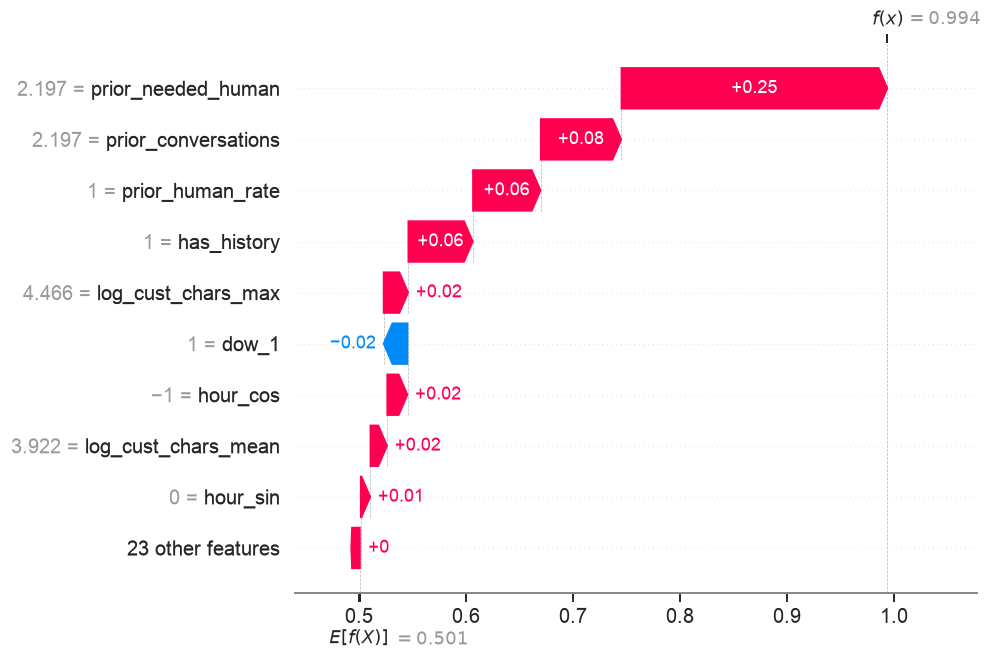


— Conversación cerca del umbral: riesgo 54%, real: necesitó persona


   ▼ Sus mensajes son muy cortos (14 caracteres en promedio) (baja 16 puntos)
   ▲ La primera respuesta automática tardó 6 s (sube 6 puntos)
   ▲ Escribió un miércoles (sube 4 puntos)

— Conversación de riesgo bajo: riesgo 5%, real: resuelta sola
   ▼ Tuvo 1 conversación anterior y no necesitó a una persona (baja 36 puntos)
   ▼ Sus mensajes son muy cortos (12 caracteres en promedio) (baja 14 puntos)
   ▲ La primera respuesta automática tardó 8 s (sube 5 puntos)
   ▲ Escribió a las 13:00 (sube 1 punto)


In [39]:
X_te_t = rf_sin_cal[:-1].transform(Xte_f)
alto = te.index[np.argmax(p_cal)]; bajo = te.index[np.argmin(p_cal)]
medio = te.index[np.argmin(np.abs(p_cal - T_ALERTA))]
for nombre, idx in [("de riesgo alto", alto), ("cerca del umbral", medio), ("de riesgo bajo", bajo)]:
    pos = te.index.get_loc(idx)
    e = shap.TreeExplainer(rf_sin_cal[-1])(X_te_t.iloc[[pos]])[:, :, 1]
    s_row = pd.Series(e.values[0], index=X_te_t.columns)
    print(f"\n— Conversación {nombre}: riesgo {p_cal[pos]:.0%}, real: {'necesitó persona' if y_te[pos] else 'resuelta sola'}")
    for frase, efecto, dir_ in explain(te.loc[idx], s_row):
        print(f"   {'▲' if dir_ == 'sube' else '▼'} {frase} ({dir_} {round(100 * abs(efecto))} punto{'' if round(100 * abs(efecto)) == 1 else 's'})")
    if nombre == "de riesgo alto":
        plt.figure(); shap.plots.waterfall(e[0], max_display=10, show=False)
        save(plt.gcf(), "16_shap_waterfall_alto"); plt.show()

## 7. Modelo final para desplegar

Con los hiperparámetros elegidos, se reentrena con **todas** las conversaciones sin E09
(julio–octubre y las anteriores). Se recalculan los umbrales con predicciones fuera de pliegue
sobre ese mismo conjunto, con las mismas metas de recall (80 % y 95 %). Se guarda:

- `models/riesgo_v1.joblib`: el artefacto `RiskModel` (modelo calibrado, modelo para SHAP,
  umbrales, tasa base de entrenamiento y lista de variables);
- `models/metrics.json`: las métricas que resume `model_card.md`.

In [40]:
final, oof_f = train_risk_model(rest, best_params, meta={"version": "riesgo_v1", "excluye": [DOMINANT]})
th, y_full = final.thresholds, rest[TARGET].values
joblib.dump(final, MODELS / "riesgo_v1.joblib", compress=3)

metrics = {
    "modelo": "Random Forest calibrado (isotónica), sin ai_chars_mean", "params": best_params,
    "umbrales_final": th, "tasa_base_entrenamiento_final": final.prior_train, "meta_final": final.meta,
    "fuera_de_pliegue_final": {"PR-AUC": float(average_precision_score(y_full, oof_f)), "ROC-AUC": float(roc_auc_score(y_full, oof_f)),
                               "recall_alerta": float(recall_score(y_full, oof_f >= th["alerta"])),
                               "precision_alerta": float(precision_score(y_full, oof_f >= th["alerta"])),
                               "pct_alertado": float((oof_f >= th["alerta"]).mean())},
    "octubre": {k: {m: float(v) for m, v in r.items()} for k, r in res_oct.T.to_dict().items()},
    "octubre_umbrales": {"alerta": T_ALERTA, "vigilar": T_VIGILAR},
    "octubre_politicas": {k: {m: float(v) for m, v in r.items()} for k, r in pol.T.to_dict().items()},
    "octubre_tasa_base": {"entrenamiento": float(PRIOR_TR), "em": float(pi_em), "real": float(y_te.mean())},
    "octubre_brier": {k: float(brier_score_loss(y_te, p)) for k, p in cal_tab.items()},
    "comparacion": R.drop(columns="params").round(4).to_dict(orient="records"),
    "por_empresa_octubre": por_emp.round(4).reset_index().to_dict(orient="records"),
    "negocio_octubre": {k: (int(v) if float(v).is_integer() else float(v)) for k, v in neg["valor"].items()},
}
json.dump(metrics, open(MODELS / "metrics.json", "w"), indent=2, ensure_ascii=False, default=float)
print(json.dumps({k: metrics[k] for k in ["umbrales_final", "tasa_base_entrenamiento_final", "fuera_de_pliegue_final"]}, indent=2))

check = joblib.load(MODELS / "riesgo_v1.joblib").risk(te.head(5))
check

{
  "umbrales_final": {
    "alerta": 0.467235298035298,
    "vigilar": 0.295403798616978
  },
  "tasa_base_entrenamiento_final": 0.5532157085941947,
  "fuera_de_pliegue_final": {
    "PR-AUC": 0.848015929323543,
    "ROC-AUC": 0.8147066190197432,
    "recall_alerta": 0.8000685871056241,
    "precision_alerta": 0.7392268694550064,
    "pct_alertado": 0.5987478656801366
  }
}


,score,riesgo,nivel
0,0.281755,0.281755,verde
2,0.443758,0.443758,amarillo
3,0.454022,0.454022,amarillo
6,0.151626,0.151626,verde
7,0.058441,0.058441,verde


## 8. Conclusiones

1. **Modelo elegido: Random Forest calibrado con isotónica, sin `ai_chars_mean`.** En octubre
   (datos nunca vistos, un mes posterior) logra **ROC-AUC 0,79 y PR-AUC 0,77, contra 0,44 al azar**.
   Con clientes nuevos, ROC-AUC 0,74. Con empresas nunca vistas, 0,69.
2. **Generaliza en el tiempo, con límites claros para negocios nuevos.** La curva de aprendizaje
   sigue subiendo, así que más meses y más empresas deberían mejorar el modelo.
3. **Quitar la huella de la empresa cuesta 0,02 de PR-AUC y no cambia nada dentro de cada empresa.**
   SHAP confirma que el 67 % de la variación del efecto de `ai_chars_mean` es la identidad de la
   empresa.
4. **Lo que más pesa es el historial del cliente**, seguido del tiempo de primera respuesta y del
   largo de sus mensajes.
5. **El cambio de octubre es de mezcla de empresas, no de proporción.** La probabilidad calibrada ya
   lo sigue (46 % predicho contra 44 % real), y la corrección por tasa base lo empeora. Se despliega
   sin corrección y se vigila la calibración por empresa.
6. **Punto de operación.** Con el umbral global, en octubre se detectan **6 de cada 10 casos** al
   cuarto mensaje, antes de cualquier intervención humana, y **7 de cada 10 alertas son correctas**,
   contra 4,4 al azar. Mirando primero el 10 % más riesgoso, 96 % de esas conversaciones
   necesitaron persona. La meta de recall 0,80 de la validación no se sostuvo en octubre por el
   cambio de mezcla. Para recuperarla conviene bajar el umbral global (precisión ≈ 0,6), no fijar
   umbrales por empresa, que quedan por debajo de la curva.
7. **El techo es la información, no el algoritmo:** dentro de cada empresa todos los modelos se
   quedan en AUC ≈ 0,64. El siguiente salto vendría de ampliar la ventana (hasta 8 mensajes), de
   señales de texto más ricas y de medir cuándo entró la persona, para cuantificar la anticipación.

# Parte 3 · Monitoreo y reentrenamiento

Punto **3.9** del enunciado. El modelo no se entrena una vez y ya: las empresas cambian su
operación, llegan negocios nuevos y cambia el modelo de IA de la plataforma. Este notebook
**simula el ciclo mensual** con los datos que ya tenemos, como si el modelo se hubiera puesto en
producción el 1 de octubre:

1. **Etiquetas automáticas:** cada conversación que termina produce su propia etiqueta
   (`needed_human`), así que no hay que etiquetar a mano.
2. **Vigilancia mensual:** cambios en los datos de entrada (PSI), recall, precisión y calibración
   por empresa.
3. **Regla de reentrenamiento:** el recall baja más de 5 puntos, entran empresas nuevas, hay un
   cambio fuerte en los datos o pasan 3 meses.
4. **Validar al retador contra el vigente** en el mismo mes y las mismas empresas; si gana, corre en
   paralelo sin afectar a nadie y luego lo reemplaza, con opción de volver atrás.

Las funciones están en `src/monitoring.py` y `src/retrain.py`, para usarlas fuera del notebook.

In [41]:
import os, sys, json, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load, time_split, TARGET, DOMINANT
from risk_model import train_risk_model
from monitoring import feature_drift, performance, performance_by_company, retrain_decision, PSI_MODERATE, PSI_HIGH
from retrain import compare, should_promote

warnings.filterwarnings("ignore")
FIG = ROOT / "figures"
C0, C1, C2, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
sns.set_theme(style="white", rc={"axes.edgecolor": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                                 "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=150)

params = json.load(open(ROOT / "models" / "best_params.json"))
df = load(ROOT / "data" / "orvyz_conversaciones_riesgo.csv")
rest = df[df.empresa != DOMINANT].reset_index(drop=True)

## 1. Modelos de cada mes

Para simular la operación, se entrena un modelo al inicio de cada mes con todo lo anterior (el
mismo procedimiento del modelo final: Random Forest calibrado, umbrales con validación anidada) y se
evalúa con las conversaciones de ese mes, que el modelo no vio.

In [42]:
MESES = ["2026-08", "2026-09", "2026-10"]
modelos, oofs = {}, {}
for m in MESES:
    train = rest[rest.fecha < pd.Period(m).start_time]
    modelos[m], oofs[m] = train_risk_model(train, params, meta={"version": f"inicio {m}"})
    print(f"Modelo de inicio de {m}: {len(train):,} conversaciones, {train.empresa.nunique()} empresas, "
          f"umbral de alerta {modelos[m].thresholds['alerta']:.3f}")

Modelo de inicio de 2026-08: 730 conversaciones, 6 empresas, umbral de alerta 0.570


Modelo de inicio de 2026-09: 945 conversaciones, 8 empresas, umbral de alerta 0.492


Modelo de inicio de 2026-10: 2,806 conversaciones, 11 empresas, umbral de alerta 0.568


## 2. Revisión mensual: octubre

El modelo vigente es el entrenado al inicio de octubre. Al cerrar el mes ya se conocen las etiquetas
de octubre, y se revisan tres cosas.

### 2.1 ¿Cambiaron los datos de entrada? (PSI)

El **PSI** (*Population Stability Index*) compara la distribución de cada variable del mes con la
de entrenamiento: $\mathrm{PSI} = \sum_i (n_i - r_i)\,\ln(n_i / r_i)$ sobre intervalos de cuantiles
de la referencia. Convención usual: < 0,10 estable, 0,10–0,25 vigilar, ≥ 0,25 cambio fuerte.
No necesita etiquetas, así que se puede calcular cada día.

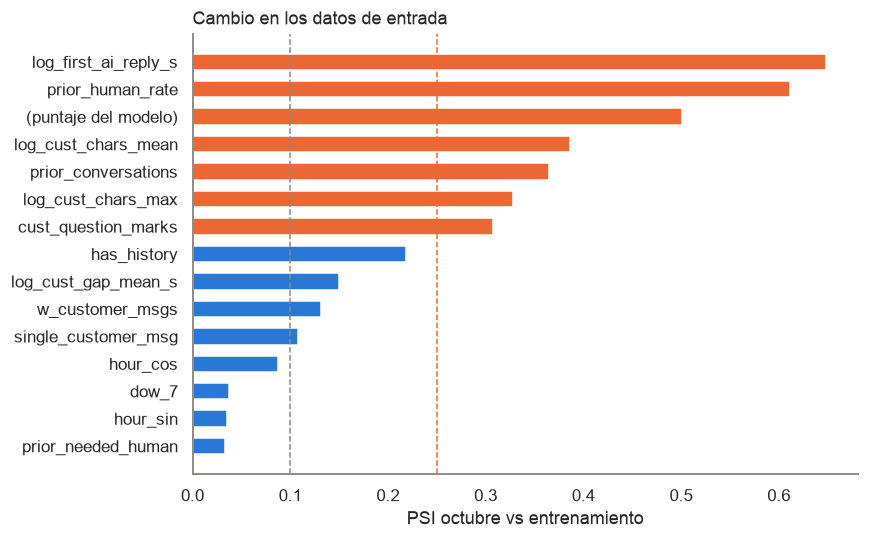

,PSI,estado
log_first_ai_reply_s,0.649,cambio fuerte
prior_human_rate,0.611,cambio fuerte
(puntaje del modelo),0.501,cambio fuerte
log_cust_chars_mean,0.387,cambio fuerte
prior_conversations,0.365,cambio fuerte
log_cust_chars_max,0.328,cambio fuerte
cust_question_marks,0.307,cambio fuerte
has_history,0.218,vigilar
log_cust_gap_mean_s,0.150,vigilar
w_customer_msgs,0.131,vigilar


In [43]:
vigente = modelos["2026-10"]
ref, octubre = rest[rest.fecha < "2026-10-01"], rest[rest.mes == "2026-10"]
drift = feature_drift(vigente, ref, octubre)
top = drift.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.PSI, color=[C1 if v >= PSI_HIGH else C0 for v in top.PSI], height=0.6)
for v, c in [(PSI_MODERATE, MUTED), (PSI_HIGH, C1)]: ax.axvline(v, color=c, ls="--", lw=1)
ax.set_xlabel("PSI octubre vs entrenamiento"); ax.set_title("Cambio en los datos de entrada", loc="left")
fig.tight_layout(); save(fig, "20_psi_octubre"); plt.show()
drift.round(3).head(15)

El PSI marca las variables cuya distribución cambió en octubre. Varias de ellas son las que
distinguen la operación de cada empresa (tiempo de respuesta, largo de los mensajes), y con E01
pasando a ser el 40 % del mes, se mueven. Las de historial (`prior_*`) cambian además de forma
natural, porque cada mes hay más clientes que vuelven. Es la
misma conclusión del EDA y del notebook 02 (cambio de mezcla), detectada aquí **sin etiquetas**: en
producción esta alarma llega días antes que la caída del recall.

### 2.2 ¿Cómo le fue al modelo? Recall, precisión y calibración por empresa

In [44]:
perf = performance_by_company(vigente, octubre)
perf.round(2)

,n,% positivos,ROC-AUC,PR-AUC,recall,precisión,% alertado,riesgo medio
TOTAL,2465.0,0.44,0.79,0.77,0.58,0.72,0.36,0.47
E01,1010.0,0.22,0.67,0.44,0.27,0.58,0.10,0.28
E02,30.0,1.00,NaN,NaN,1.00,1.00,1.00,0.94
E04,109.0,0.61,0.62,0.70,0.50,0.72,0.42,0.54
E06,427.0,0.34,0.59,0.48,0.37,0.49,0.26,0.44
E07,169.0,0.99,0.74,1.00,0.99,0.99,0.99,0.91
E08,60.0,0.95,0.91,0.99,0.95,0.98,0.92,0.87
E10,179.0,0.84,0.73,0.91,0.52,0.95,0.46,0.56
E11,17.0,0.06,0.12,0.07,0.00,0.00,0.59,0.59
E12,464.0,0.56,0.58,0.64,0.64,0.59,0.60,0.59


En la columna *riesgo medio* contra *% positivos* se lee la calibración de cada empresa. Las
empresas con pocas conversaciones en el mes tienen métricas muy ruidosas; en producción se
reportan solo con un mínimo de casos (por ejemplo, 30) o acumulando varios meses.

### 2.3 Decisión

In [45]:
ref_recall = float(((oofs["2026-10"] >= vigente.thresholds["alerta"]) & (ref[TARGET].values == 1)).sum() / ref[TARGET].sum())
decision = retrain_decision(vigente, ref_recall, perf, drift, months_since_training=1)
print("Recall de referencia (validación fuera de pliegue):", round(ref_recall, 3))
print("¿Reentrenar?", "SÍ" if decision["reentrenar"] else "no")
for r in decision["motivos"]: print("  -", r)

Recall de referencia (validación fuera de pliegue): 0.8
¿Reentrenar? SÍ
  - el recall bajó 22 puntos (0.80 → 0.58)
  - cambio fuerte (PSI ≥ 0.25) en: log_first_ai_reply_s, prior_human_rate, (puntaje del modelo), log_cust_chars_mean, prior_conversations, log_cust_chars_max, cust_question_marks


## 3. Seguimiento mes a mes

La misma revisión aplicada a agosto, septiembre y octubre, cada mes con el modelo entrenado al
inicio de ese mes. Muestra cómo evoluciona el modelo a medida que llegan datos y empresas.

,n,% positivos,ROC-AUC,PR-AUC,recall,precisión,% alertado,riesgo medio,PSI del puntaje,empresas nuevas
2026-08,215.0,0.419,0.811,0.799,0.856,0.558,0.642,0.674,0.239,2.0
2026-09,1861.0,0.643,0.544,0.688,0.602,0.655,0.591,0.588,0.718,3.0
2026-10,2465.0,0.445,0.786,0.770,0.583,0.723,0.359,0.465,0.501,0.0


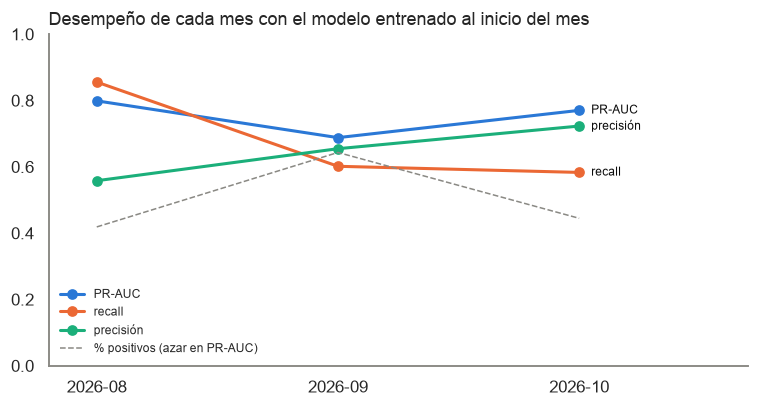

In [46]:
filas = []
for m in MESES:
    mod, mes = modelos[m], rest[rest.mes == m]
    p = performance(mes[TARGET], mod.score(mes), mod.thresholds["alerta"])
    previo = rest[rest.fecha < pd.Period(m).start_time]
    p["PSI del puntaje"] = feature_drift(mod, previo, mes).loc["(puntaje del modelo)", "PSI"]
    p["empresas nuevas"] = len(set(mes.empresa) - set(previo.empresa))
    filas.append(pd.Series(p, name=m))
mensual = pd.DataFrame(filas)
display(mensual.round(3))

fig, ax = plt.subplots(figsize=(7, 3.8))
for col, c in [("PR-AUC", C0), ("recall", C1), ("precisión", C2)]:
    ax.plot(mensual.index, mensual[col], marker="o", lw=2, color=c, label=col)
    ax.text(len(mensual) - 0.95, mensual[col].iloc[-1], col, color=INK, fontsize=8, va="center")
ax.plot(mensual.index, mensual["% positivos"], color=MUTED, ls="--", lw=1, label="% positivos (azar en PR-AUC)")
ax.set_ylim(0, 1); ax.set_xlim(-0.2, len(mensual) - 0.3); ax.legend(frameon=False, fontsize=8, loc="lower left")
ax.set_title("Desempeño de cada mes con el modelo entrenado al inicio del mes", loc="left")
fig.tight_layout(); save(fig, "21_seguimiento_mensual"); plt.show()

- **Septiembre es el peor mes (ROC-AUC ≈ 0,54):** llegan 3 empresas que el modelo de agosto nunca
  vio y que suman la mayoría de las conversaciones del mes. El PSI del puntaje lo había anunciado
  (≈ 0,7, cambio fuerte). Es la razón de la regla "reentrenar cuando entran empresas nuevas".
- **Agosto** sale bien en orden (ROC-AUC ≈ 0,81), pero con solo 215 conversaciones.
- **Octubre**, con septiembre ya en el entrenamiento, se recupera a ROC-AUC ≈ 0,79.
- Cada mes cambia la mezcla de empresas y, con ella, el recall que se obtiene con un umbral fijo.
  Además, el umbral elegido varía unas centésimas según cómo se armen los pliegues (0,54 en el
  notebook 02 y 0,57 aquí, con la misma meta de recall). Por eso el umbral se revisa en cada
  reentrenamiento y se reporta junto con su volumen de alertas.

## 4. Retador contra vigente

El vigente es el modelo del 1 de septiembre. El retador se entrena el 1 de octubre con septiembre
incluido. Se comparan **en el mismo mes (octubre), con las mismas conversaciones**, ninguna vista
por los dos modelos. Regla (`src/retrain.py`): el retador reemplaza al vigente si gana en PR-AUC y
no pierde más de 2 puntos de recall **alertando el mismo volumen de conversaciones que el vigente**.

¿Por qué a igual volumen? El recall de cada modelo con su propio umbral mezcla dos cosas: qué tan
bien ordena y dónde quedó el corte. Un retador que ordena mejor pero eligió un umbral más alto
parecería peor. A igual volumen, la comparación es justa: con la misma carga de trabajo para el
equipo, ¿cuál detecta más casos? El umbral del ganador se revisa aparte.

In [47]:
resumen, por_empresa = compare(modelos["2026-09"], modelos["2026-10"], octubre)
display(resumen.round(3))
display(por_empresa.round(3))
c, v = resumen.loc["retador"], resumen.loc["vigente"]
print("Promover retador:", "SÍ" if should_promote(resumen) else "no",
      f"(PR-AUC {v['PR-AUC']:.3f} → {c['PR-AUC']:.3f}; recall a igual volumen "
      f"{v['recall a igual volumen']:.3f} → {c['recall a igual volumen']:.3f})")

,n,% positivos,ROC-AUC,PR-AUC,recall,precisión,% alertado,riesgo medio,recall a igual volumen
vigente,2465.0,0.445,0.717,0.657,0.647,0.618,0.465,0.538,0.647
retador,2465.0,0.445,0.786,0.770,0.583,0.723,0.359,0.465,0.705


,vigente,retador
E01,0.639,0.672
E02,NaN,NaN
E04,0.700,0.623
E06,0.590,0.593
E07,0.533,0.743
E08,0.942,0.912
E10,0.710,0.733
E11,0.312,0.125
E12,0.530,0.578


Promover retador: SÍ (PR-AUC 0.657 → 0.770; recall a igual volumen 0.647 → 0.705)


## 5. Ciclo en producción

| Paso | Cuándo | Qué |
|---|---|---|
| Puntuar | En cada conversación, al llegar al 4.º mensaje sin intervención humana | `RiskModel.risk()` → riesgo, semáforo y razones. Se guarda el puntaje y la versión del modelo. |
| Etiquetar | Al cerrar la conversación | `needed_human` se calcula solo, con la misma definición del conjunto de datos. |
| Vigilar datos | Diario | PSI de variables y del puntaje (no necesita etiquetas). |
| Vigilar desempeño | Mensual | `performance_by_company`: recall, precisión, PR-AUC y calibración por empresa. Además, el **tiempo entre la alerta y el primer mensaje humano**, la medida de anticipación que el conjunto anonimizado no permite calcular. |
| Decidir | Mensual | `retrain_decision`: recall −5 puntos, empresas nuevas, PSI ≥ 0,25, descalibración > 5 puntos o 3 meses. |
| Reentrenar | Si la regla lo pide | `python src/retrain.py --holdout <mes>`: retador contra vigente en el último mes. |
| Desplegar | Si el retador gana | Corre **en paralelo** una o dos semanas, guardando ambos puntajes sin mostrar el nuevo; luego reemplaza al vigente. El artefacto anterior se conserva para **volver atrás** con un cambio de configuración. |

**Cuidados:**
- No reentrenar con conversaciones aún abiertas: su etiqueta no es definitiva.
- El historial del cliente (`prior_*`) solo debe contar conversaciones **cerradas** antes de la actual.
- Si cambia el modelo de IA de la plataforma, se reentrena aunque las métricas no hayan caído, porque
  cambia la forma de las respuestas automáticas.

## 6. Conclusiones
1. **El monitoreo detecta el problema sin etiquetas.** En octubre el PSI del puntaje fue 0,50
   (cambio fuerte) y en septiembre 0,72, antes de conocer cuántas conversaciones necesitaron
   persona.
2. **Con etiquetas, la regla pide reentrenar en octubre:** el recall cae de 0,80 (validación) a
   ≈ 0,58, y siete variables tienen PSI ≥ 0,25.
3. **Reentrenar sirve:** el retador del 1 de octubre, que incluye septiembre, le gana al modelo del 1
   de septiembre en el mismo octubre: PR-AUC 0,66 → 0,77 y más recall con la misma carga de alertas.
4. **La regla de promoción compara a igual volumen de alertas**, para no castigar a un retador que
   ordena mejor solo porque su umbral cayó en otro punto. Esto salió de este mismo análisis: con la
   comparación ingenua de recall, el retador se habría rechazado.
5. **Las empresas nuevas son el mayor riesgo** (septiembre, ROC-AUC 0,54). Con un negocio nuevo, el
   modelo se usa para ordenar la cola, no para alertar, hasta tener un mes de datos suyos.